# 🌱 Eco Lifestyle Predictor — Sustainability Rating Classification and Recommendations

**Course / context:** Second-year B.Tech AIML internship project  
**Task:** (1) Predict a participant's lifestyle **sustainability rating category** (Low / Medium / High) from 17 lifestyle features, and (2) generate **personalised, rule-based sustainability suggestions** from the same 17 answers (Phase 3, Section 11). The two parts are kept logically separate.

### Notebook outline
1. Setup and data loading  
2. Dataset audit  
3. Target and feature definition  
4. Exploratory data analysis (EDA)  
5. Train/test split and preprocessing pipeline  
6. Model comparison with cross-validation  
7. Hyperparameter tuning, final test evaluation and supplementary group-aware cross-validation  
8. Model interpretation (feature importance, permutation importance, predicted probabilities)  
9. *Supplementary:* Linear Regression experiment  
10. Limitations and summary  
11. Personalised recommendation engine (Phase 3)  
12. Original figures restored, with chart inventory

### How to run
* **Google Colab:** run the loading cell and upload `lifestyle_sustainability_data.csv` when prompted.  
* **Local Jupyter:** place `lifestyle_sustainability_data.csv` in the same folder as this notebook (or in `data/` or `../data/`) and run all cells top to bottom.  
* Required libraries: `numpy`, `pandas`, `matplotlib`, `seaborn`, `scikit-learn` (all pre-installed on Colab).

## 1. Setup and data loading

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (make_scorer, accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix,
                             mean_squared_error, mean_absolute_error, r2_score)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1


In [ ]:
# ---- Dataset loading (works in Google Colab and local Jupyter) ----
DATA_FILE = "lifestyle_sustainability_data.csv"

# Places to look for the file, in this order
candidates = [DATA_FILE,   
              os.path.join("data", DATA_FILE),       
              os.path.join("..", "data", DATA_FILE),   
              os.path.join("/content", DATA_FILE),  
              os.path.join("..", DATA_FILE)] 
data_path = next((p for p in candidates if os.path.exists(p)), None)

# If not found and we are in Google Colab, ask the user to upload it
if data_path is None:
    try:
        from google.colab import files     
        print("Dataset not found. Please upload", DATA_FILE)
        files.upload()
        data_path = DATA_FILE if os.path.exists(DATA_FILE) else None
    except ImportError:
        pass

if data_path is None:
    raise FileNotFoundError(
        f"Could not find '{DATA_FILE}'. Put it next to this notebook (or in a 'data/' folder), "
        "or run in Google Colab and upload it when asked.")

df = pd.read_csv(data_path, keep_default_na=False, na_values=[""])
print("Loaded:", data_path)
print("Shape :", df.shape)
df.head()

Loaded: lifestyle_sustainability_data.csv
Shape : (499, 20)


,ParticipantID,Age,Location,DietType,LocalFoodFrequency,TransportationMode,EnergySource,HomeType,HomeSize,ClothingFrequency,SustainableBrands,EnvironmentalAwareness,CommunityInvolvement,MonthlyElectricityConsumption,MonthlyWaterConsumption,Gender,UsingPlasticProducts,DisposalMethods,PhysicalActivities,Rating
0,1,35,Urban,Mostly Plant-Based,Often,Bike,Renewable,Apartment,800,Rarely,True,5,High,100,1500,Female,Rarely,Composting,High,5
1,2,28,Suburban,Balanced,Sometimes,Public Transit,Mixed,House,1500,Sometimes,True,4,Moderate,250,3000,Male,Sometimes,Recycling,Moderate,4
2,3,65,Rural,Mostly Animal-Based,Rarely,Car,Non-Renewable,House,2500,Often,False,2,Low,400,4500,Male,Often,Landfill,Low,1
3,4,42,Urban,Mostly Plant-Based,Often,Walk,Renewable,Apartment,950,Sometimes,True,4,Moderate,150,2000,Female,Rarely,Recycling,High,5
4,5,31,Suburban,Balanced,Sometimes,Public Transit,Mixed,House,1800,Often,True,3,Low,300,3500,Non-Binary,Sometimes,Combination,Moderate,3


## 2. Dataset audit

Before modelling, we check the structure and quality of the data. **No records are modified** — the audit only reports what is there.

In [3]:
print("Shape (rows, columns):", df.shape)
print("\nData types:")
print(df.dtypes.to_string())

Shape (rows, columns): (499, 20)

Data types:
ParticipantID                    int64
Age                              int64
Location                           str
DietType                           str
LocalFoodFrequency                 str
TransportationMode                 str
EnergySource                       str
HomeType                           str
HomeSize                         int64
ClothingFrequency                  str
SustainableBrands                 bool
EnvironmentalAwareness           int64
CommunityInvolvement               str
MonthlyElectricityConsumption    int64
MonthlyWaterConsumption          int64
Gender                             str
UsingPlasticProducts               str
DisposalMethods                    str
PhysicalActivities                 str
Rating                           int64


In [ ]:
# ---- Missing values ----
print("Truly missing (empty) cells per column, with 'None' kept as a category:")
print(df.isna().sum().to_string())
print("\nTotal missing cells:", int(df.isna().sum().sum()))

# What happens with pandas' DEFAULT reading?
df_default = pd.read_csv(data_path)
default_na = df_default.isna().sum()
print("\nNaN counts if pandas' default parser is used:")
print(default_na[default_na > 0].to_string())

lit_none = (df[["CommunityInvolvement", "PhysicalActivities"]] == "None").sum()
print("\nRows containing the literal text 'None':")
print(lit_none.to_string())

Truly missing (empty) cells per column, with 'None' kept as a category:
ParticipantID                    0
Age                              0
Location                         0
DietType                         0
LocalFoodFrequency               0
TransportationMode               0
EnergySource                     0
HomeType                         0
HomeSize                         0
ClothingFrequency                0
SustainableBrands                0
EnvironmentalAwareness           0
CommunityInvolvement             0
MonthlyElectricityConsumption    0
MonthlyWaterConsumption          0
Gender                           0
UsingPlasticProducts             0
DisposalMethods                  0
PhysicalActivities               0
Rating                           0

Total missing cells: 0

NaN counts if pandas' default parser is used:
CommunityInvolvement    118
PhysicalActivities      108

Rows containing the literal text 'None':
CommunityInvolvement    118
PhysicalActivities      108


**Finding:** the "missing values" reported by the default parser in `CommunityInvolvement` and `PhysicalActivities` are in fact the **text category `"None"`** (e.g. "no community involvement", "no physical activity"), not empty cells. The counts match exactly. The original notebook relabelled these as `"Unknown"`, which changed their meaning. Here they are kept as the genuine category `"None"`. The dataset has **no truly missing values**; the imputers in the pipeline below are kept only as a safeguard for future, unseen data.

In [5]:
# ---- Duplicates: three DIFFERENT definitions, reported separately ----
feat17 = [c for c in df.columns if c not in ("ParticipantID", "Gender", "Rating")]   # the 17 lifestyle features
cols_wo_id = [c for c in df.columns if c != "ParticipantID"]

print("ParticipantID unique?  :", df["ParticipantID"].is_unique)
print("IDs missing from 1..500:", sorted(set(range(1, 501)) - set(df["ParticipantID"])))

# (1) Exact duplicate rows: every column identical, including ParticipantID
n_exact = int(df.duplicated().sum())

# (2) Duplicates excluding ParticipantID: the other 19 columns identical (this INCLUDES Gender and Rating)
dup_wo_id_mask = df.duplicated(subset=cols_wo_id, keep=False)
n_dup_wo_id_extra = int(df.duplicated(subset=cols_wo_id).sum())

# (3) Repeated lifestyle PROFILES: identical on the 17 lifestyle features only (Gender and Rating ignored)
profile_stats = df.groupby(feat17, dropna=False).agg(n_rows=("Rating", "size"),
                                                     n_ratings=("Rating", "nunique"))
repeated = profile_stats[profile_stats["n_rows"] > 1]
dup_report = pd.DataFrame({
    "Definition": ["1. Exact duplicate rows (all 20 columns)",
                   "2. Duplicates excluding ParticipantID (other 19 columns)",
                   "3. Repeated profiles on the 17 lifestyle features"],
    "Repeated groups": [int(df[df.duplicated(keep=False)].groupby(list(df.columns)).ngroups) if n_exact else 0,
                        int(df[dup_wo_id_mask].groupby(cols_wo_id, dropna=False).ngroups) if dup_wo_id_mask.any() else 0,
                        len(repeated)],
    "Rows involved": [n_exact, int(dup_wo_id_mask.sum()), int(repeated["n_rows"].sum())],
    "Extra repeated rows": [n_exact, n_dup_wo_id_extra, int((repeated["n_rows"] - 1).sum())]}).set_index("Definition")
display(dup_report)
print("Distinct 17-feature profiles:", len(profile_stats), "of", len(df), "rows")
print("Largest repeated-profile group size:", int(repeated["n_rows"].max()))
print("Repeated profiles whose rows have CONFLICTING ratings (1-5 scale):", int((repeated["n_ratings"] > 1).sum()))

ParticipantID unique?  : True
IDs missing from 1..500: [488]


,Repeated groups,Rows involved,Extra repeated rows
Definition,,,
1. Exact duplicate rows (all 20 columns),0,0,0
2. Duplicates excluding ParticipantID (other 19 columns),38,77,39
3. Repeated profiles on the 17 lifestyle features,40,81,41


Distinct 17-feature profiles: 458 of 499 rows
Largest repeated-profile group size: 3
Repeated profiles whose rows have CONFLICTING ratings (1-5 scale): 0


**How to read the three definitions** (they are different questions):
1. *Exact duplicates* — whole rows copied, including the ID. **None** exist (the ID is unique).
2. *Duplicates excluding `ParticipantID`* — the same person-record under a new ID, including the same `Gender` and `Rating`.
3. *Repeated lifestyle profiles* — the same 17 lifestyle answers, whatever the gender or rating. This is the definition that matters for machine learning, because an identical profile in both the training and test data lets a model "remember" an answer instead of generalising. Profiles that repeat all received the **same rating**, so there are no conflicts — but they are still extra rows carrying no new information.

No rows were removed (the dataset must not be modified). Section 7 therefore adds a group-aware cross-validation check, and Section 10 measures the effect on the test set.

In [6]:
# ---- Categorical values and Rating distribution ----
cat_audit_cols = df.select_dtypes(include=["object", "string", "bool"]).columns
for c in cat_audit_cols:
    print(f"{c:22s}", df[c].value_counts().to_dict())

print("\nRating distribution (original 1-5 scale):")
rating_counts = df["Rating"].value_counts().sort_index()
print(pd.DataFrame({"count": rating_counts, "percent": (rating_counts / len(df) * 100).round(1)}).to_string())

Location               {'Urban': 190, 'Suburban': 156, 'Rural': 153}
DietType               {'Mostly Plant-Based': 197, 'Balanced': 158, 'Mostly Animal-Based': 144}
LocalFoodFrequency     {'Often': 148, 'Sometimes': 136, 'Rarely': 132, 'Always': 83}
TransportationMode     {'Car': 140, 'Public Transit': 123, 'Bike': 119, 'Walk': 117}
EnergySource           {'Renewable': 183, 'Mixed': 164, 'Non-Renewable': 152}
HomeType               {'House': 228, 'Apartment': 153, 'Other': 118}
ClothingFrequency      {'Often': 148, 'Sometimes': 129, 'Rarely': 115, 'Always': 107}
SustainableBrands      {True: 263, False: 236}
CommunityInvolvement   {'Moderate': 133, 'High': 130, 'Low': 118, 'None': 118}
Gender                 {'Male': 176, 'Female': 167, 'Non-Binary': 81, 'Prefer not to say': 75}
UsingPlasticProducts   {'Often': 144, 'Rarely': 142, 'Sometimes': 118, 'Never': 95}
DisposalMethods        {'Recycling': 145, 'Landfill': 141, 'Composting': 124, 'Combination': 89}
PhysicalActivities     {'Mode

In [7]:
# ---- Statistical summary (retained from the original notebook) ----
display(df.describe().round(2))
print(f"Average age                        : {df['Age'].mean():.2f}")
print(f"Average monthly electricity (kWh)  : {df['MonthlyElectricityConsumption'].mean():.2f}")
print(f"Average monthly water (litres)     : {df['MonthlyWaterConsumption'].mean():.2f}")
print(f"Average home size (sq ft)          : {df['HomeSize'].mean():.2f}")

,ParticipantID,Age,HomeSize,EnvironmentalAwareness,MonthlyElectricityConsumption,MonthlyWaterConsumption,Rating
count,499.00,499.00,499.00,499.00,499.00,499.00,499.00
mean,250.02,44.05,1518.05,3.06,291.96,3139.52,3.43
std,144.23,14.90,672.21,1.34,120.48,1224.61,1.50
min,1.00,18.00,407.00,1.00,55.00,536.00,1.00
25%,125.50,31.00,951.50,2.00,185.00,2000.00,2.00
50%,250.00,44.00,1450.00,3.00,295.00,3350.00,4.00
75%,374.50,58.00,1995.00,4.00,400.00,4100.00,5.00
max,500.00,96.00,2997.00,5.00,498.00,5250.00,5.00


Average age                        : 44.05
Average monthly electricity (kWh)  : 291.96
Average monthly water (litres)     : 3139.52
Average home size (sq ft)          : 1518.05


### Do the ratings look rule-based?
The first rows of the file show very regular "profiles" (for example *Mostly Plant-Based + Renewable energy + Bike + High awareness → 5*). We check this **descriptively**, without assuming how the data was produced.

In [8]:
# How strongly do a few single features line up with the rating?
for col in ["EnvironmentalAwareness", "DietType", "EnergySource"]:
    print(f"\nRow-wise % of each Rating within {col}:")
    display((pd.crosstab(df[col], df["Rating"], normalize="index") * 100).round(1))


Row-wise % of each Rating within EnvironmentalAwareness:


Rating,1,2,3,4,5
EnvironmentalAwareness,,,,,
1,54.3,9.9,8.6,7.4,19.8
2,43.1,15.7,11.8,9.8,19.6
3,4.5,5.5,62.7,15.5,11.8
4,0.0,2.6,6.8,37.6,53.0
5,4.5,1.1,5.6,15.7,73.0



Row-wise % of each Rating within DietType:


Rating,1,2,3,4,5
DietType,,,,,
Balanced,7.6,12.7,36.7,24.7,18.4
Mostly Animal-Based,56.2,6.9,8.3,11.8,16.7
Mostly Plant-Based,2.0,2.0,15.7,17.8,62.4



Row-wise % of each Rating within EnergySource:


Rating,1,2,3,4,5
EnergySource,,,,,
Mixed,5.5,6.1,44.5,16.5,27.4
Non-Renewable,54.6,10.5,9.2,9.2,16.4
Renewable,2.7,4.4,7.7,27.3,57.9


**Reading this carefully:** identical profiles that appear more than once received identical ratings, and some single features (diet, energy source, awareness) line up strongly with the rating. This is consistent with ratings that follow fairly regular patterns in this particular file, **but it does not prove how the data was created** — we do not know its provenance, and we make no claim about it. It does mean the dataset is small and highly structured, which affects how far results can be generalised (see Section 10).

## 3. Target and feature definition

**Target (used everywhere in this notebook):** `Rating` 1–2 → **Low**, 3 → **Medium**, 4–5 → **High**.

**Features:** `ParticipantID` (just an identifier), `Gender` (personal attribute, not a lifestyle choice) and the original `Rating` (it *is* the target) are excluded. The remaining **17 lifestyle features** are used. `EnvironmentalAwareness` is an ordered 1–5 scale, so it is treated as a **numerical** feature.

In [9]:
CLASS_ORDER = ["Low", "Medium", "High"]
rating_to_class = {1: "Low", 2: "Low", 3: "Medium", 4: "High", 5: "High"}

df["RatingClass"] = df["Rating"].map(rating_to_class)
assert df["RatingClass"].notna().all(), "Unexpected Rating value found"

y_class = df["RatingClass"]          # classification target (strings)
y_rating = df["Rating"]              # numeric rating, used ONLY by the supplementary regression section

excluded = ["ParticipantID", "Gender", "Rating", "RatingClass"]
X = df.drop(columns=excluded).copy()
# SustainableBrands is True/False -> make it text so it is handled as a category
X["SustainableBrands"] = X["SustainableBrands"].astype(str)

numeric_features = ["Age", "HomeSize", "EnvironmentalAwareness",
                    "MonthlyElectricityConsumption", "MonthlyWaterConsumption"]
categorical_features = [c for c in X.columns if c not in numeric_features]

assert len(X.columns) == 17, X.columns
assert not {"ParticipantID", "Gender", "Rating"} & set(X.columns)

print("Number of features:", X.shape[1])
print("Numerical  (", len(numeric_features), "):", numeric_features)
print("Categorical(", len(categorical_features), "):", categorical_features)

counts = y_class.value_counts().reindex(CLASS_ORDER)
print("\nClass distribution:")
print(pd.DataFrame({"count": counts, "percent": (counts / len(df) * 100).round(1)}).to_string())

Number of features: 17
Numerical  ( 5 ): ['Age', 'HomeSize', 'EnvironmentalAwareness', 'MonthlyElectricityConsumption', 'MonthlyWaterConsumption']
Categorical( 12 ): ['Location', 'DietType', 'LocalFoodFrequency', 'TransportationMode', 'EnergySource', 'HomeType', 'ClothingFrequency', 'SustainableBrands', 'CommunityInvolvement', 'UsingPlasticProducts', 'DisposalMethods', 'PhysicalActivities']

Class distribution:
             count  percent
RatingClass                
Low            131     26.3
Medium         101     20.2
High           267     53.5


## 4. Exploratory data analysis (EDA)

EDA is **descriptive** and uses all 499 rows; nothing is fitted here. Existing plots are kept and extended: rating distribution, categorical distributions, lifestyle variables versus rating, numerical distributions and the correlation heatmap.

### 4.1 Rating distribution

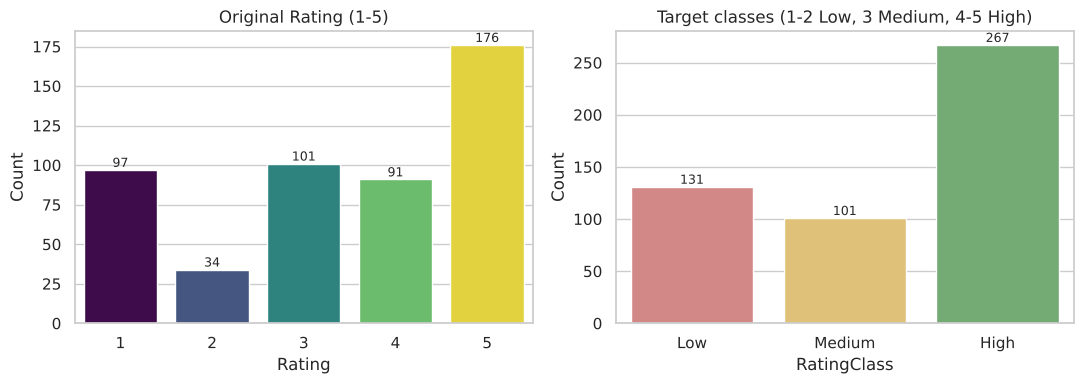

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.countplot(x="Rating", data=df, hue="Rating", palette="viridis", legend=False, ax=axes[0])
axes[0].set_title("Original Rating (1-5)")
axes[0].set_ylabel("Count")
for p in axes[0].patches:
    axes[0].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha="center", va="bottom", fontsize=9)

sns.countplot(x="RatingClass", data=df, order=CLASS_ORDER, hue="RatingClass", hue_order=CLASS_ORDER,
              palette={"Low": "#e07b7b", "Medium": "#f0c869", "High": "#6bb36b"}, legend=False, ax=axes[1])
axes[1].set_title("Target classes (1-2 Low, 3 Medium, 4-5 High)")
axes[1].set_xlabel("RatingClass"); axes[1].set_ylabel("Count")
for p in axes[1].patches:
    axes[1].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

The classes are **imbalanced**: High is the largest group and Medium the smallest. A model that always predicts "High" would already look decent on plain accuracy, which is why a dummy baseline and **macro** metrics are used later.

### 4.2 Categorical lifestyle distributions

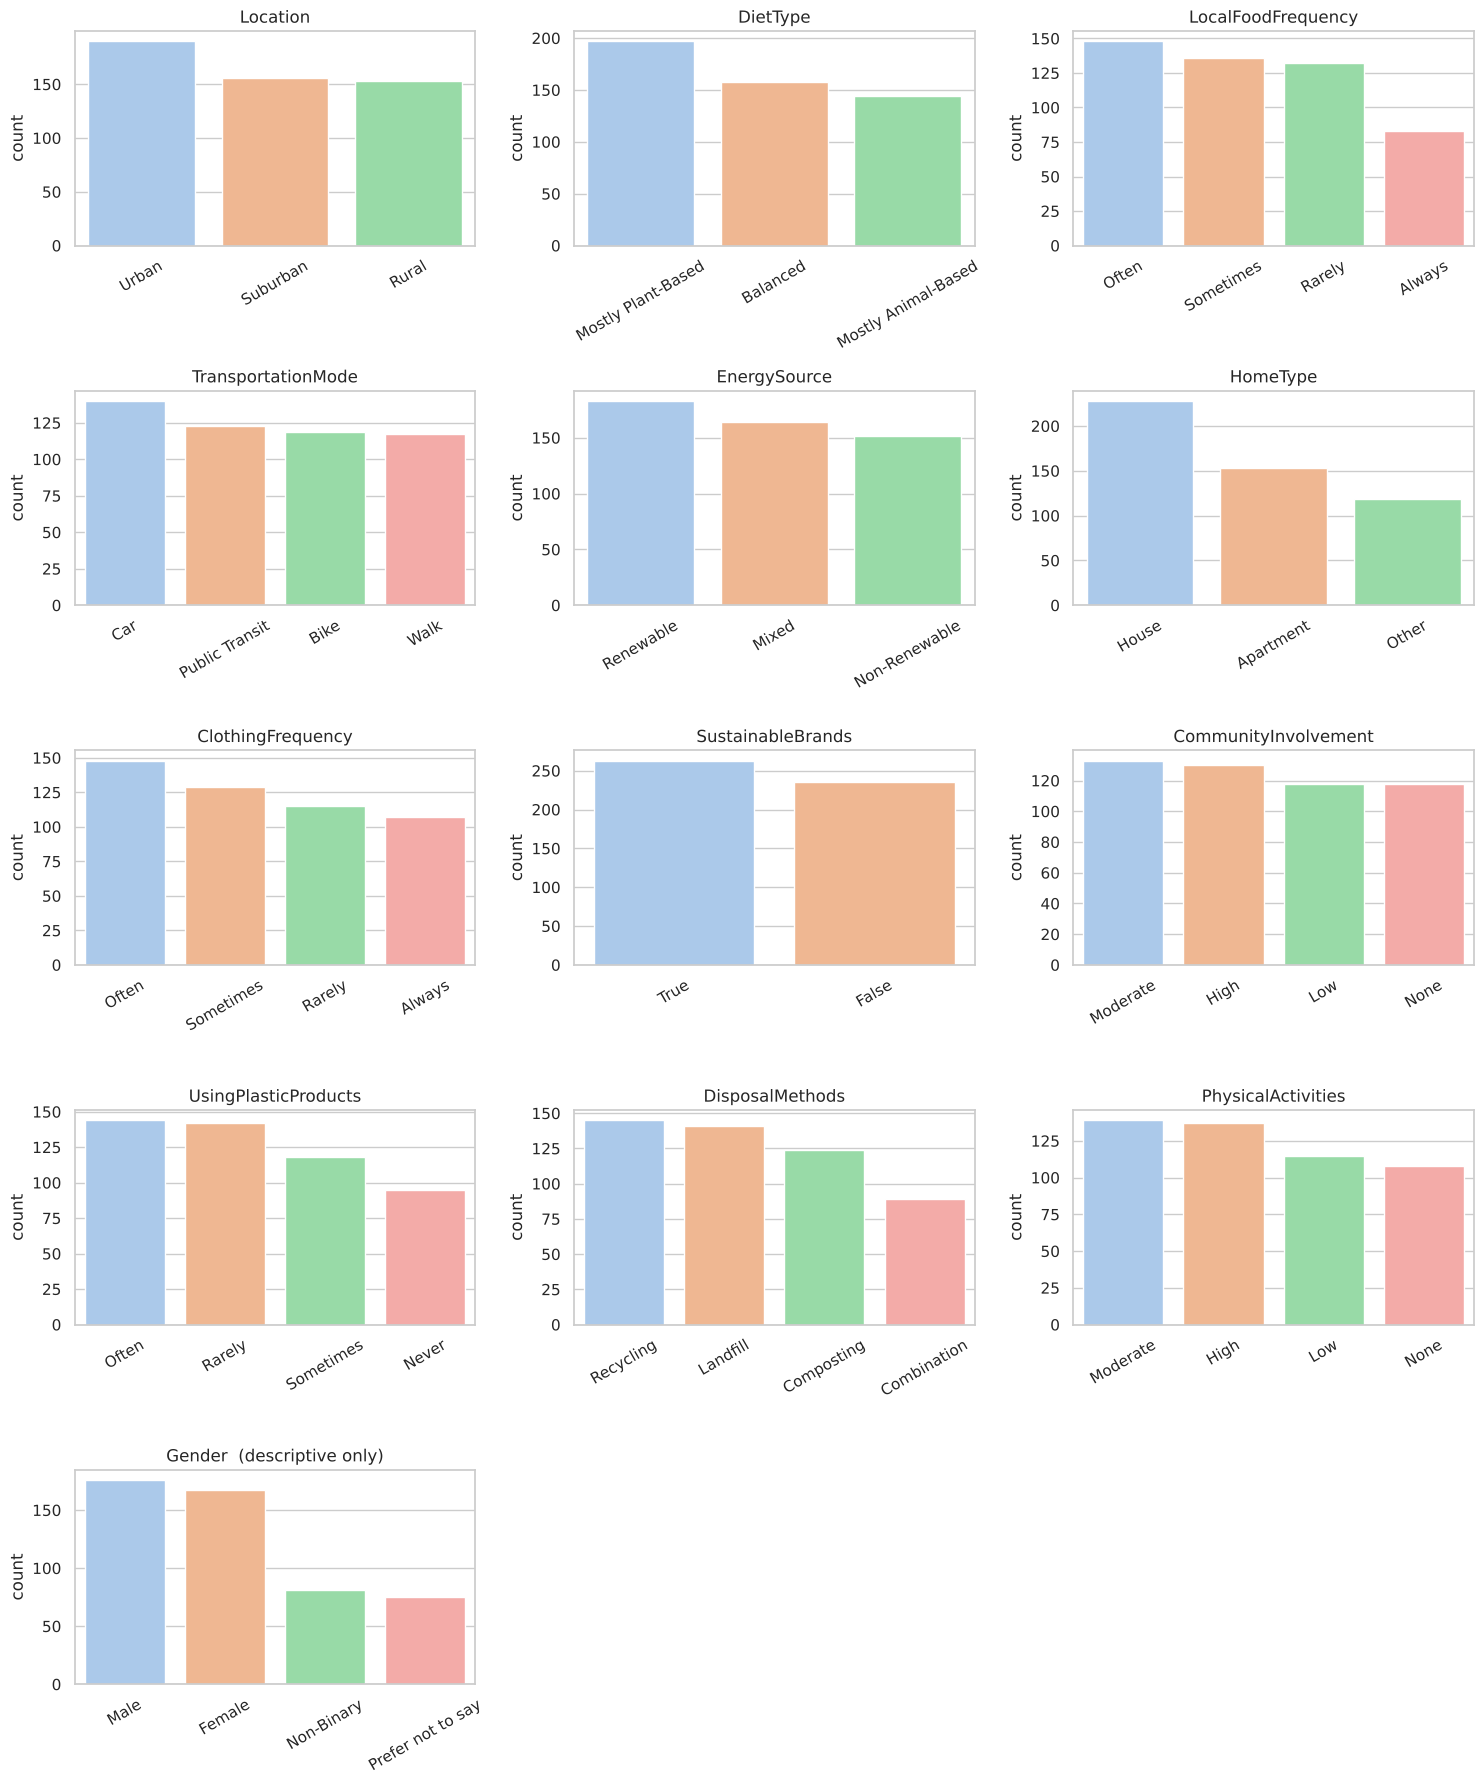

In [11]:
cat_plot_cols = categorical_features + ["Gender"]   # Gender shown for description only; it is NOT a model feature
n_cols = 3
n_rows = int(np.ceil(len(cat_plot_cols) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 3.6 * n_rows))
for ax, col in zip(axes.ravel(), cat_plot_cols):
    order = df[col].astype(str).value_counts().index
    sns.countplot(x=df[col].astype(str), order=order, hue=df[col].astype(str), hue_order=order,
                  palette="pastel", legend=False, ax=ax)
    ax.set_title(col + ("  (descriptive only)" if col == "Gender" else ""))
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
for ax in axes.ravel()[len(cat_plot_cols):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

### 4.3 Lifestyle variables versus rating class

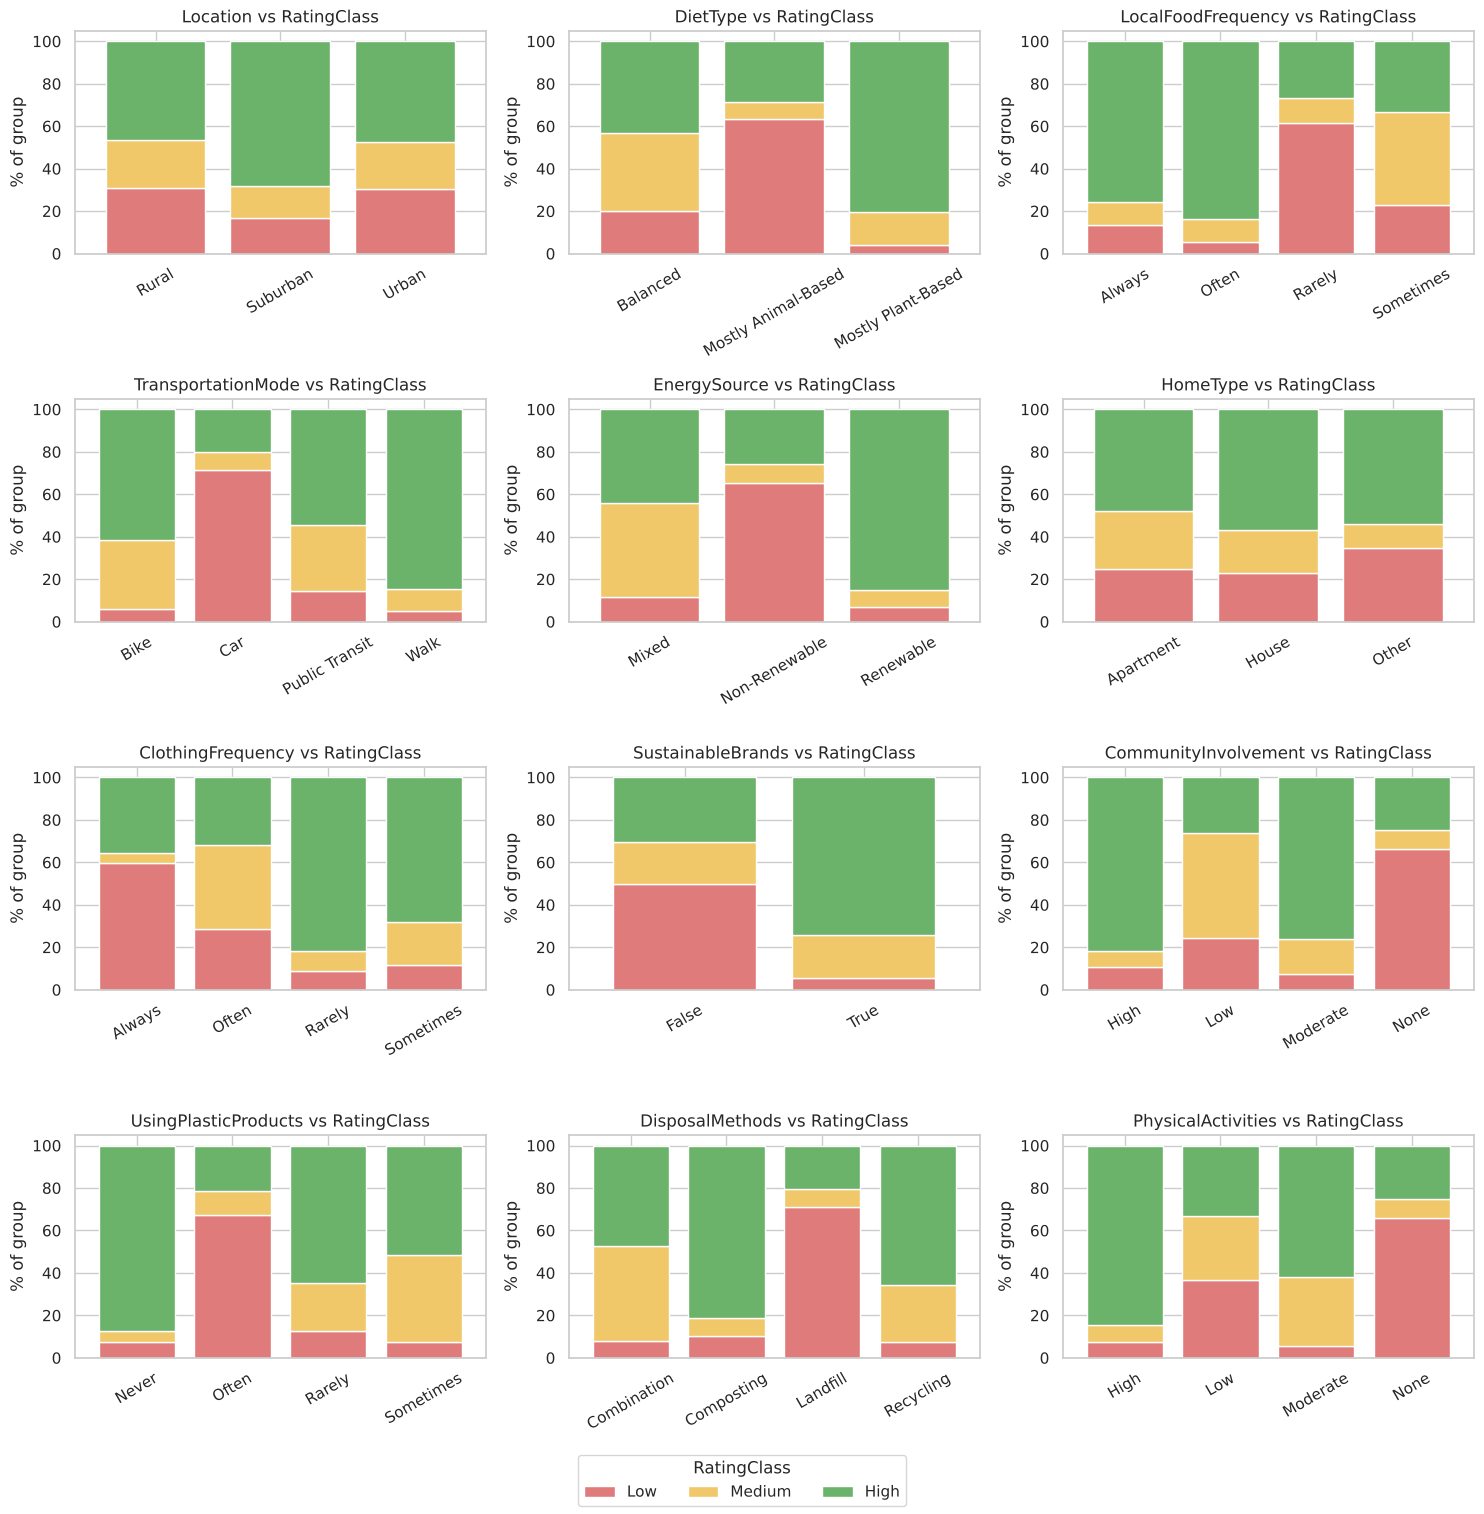

In [12]:
# Share of each rating class within every category (rows sum to 100%)
class_colors = {"Low": "#e07b7b", "Medium": "#f0c869", "High": "#6bb36b"}
vs_cols = [c for c in categorical_features]
n_cols = 3
n_rows = int(np.ceil(len(vs_cols) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 3.8 * n_rows))
for ax, col in zip(axes.ravel(), vs_cols):
    tab = pd.crosstab(X[col], y_class, normalize="index").reindex(columns=CLASS_ORDER) * 100
    tab.plot(kind="bar", stacked=True, ax=ax, color=[class_colors[c] for c in CLASS_ORDER], legend=False, width=0.8)
    ax.set_title(f"{col} vs RatingClass")
    ax.set_xlabel(""); ax.set_ylabel("% of group")
    ax.tick_params(axis="x", rotation=30)
for ax in axes.ravel()[len(vs_cols):]:
    ax.set_visible(False)
handles, labels = axes.ravel()[0].get_legend_handles_labels()
plt.tight_layout(rect=[0, 0.04, 1, 1])
fig.legend(handles, labels, loc="lower center", ncol=3, title="RatingClass")
plt.show()

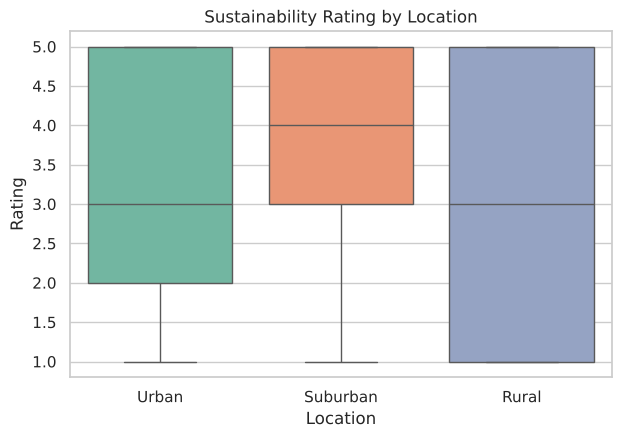

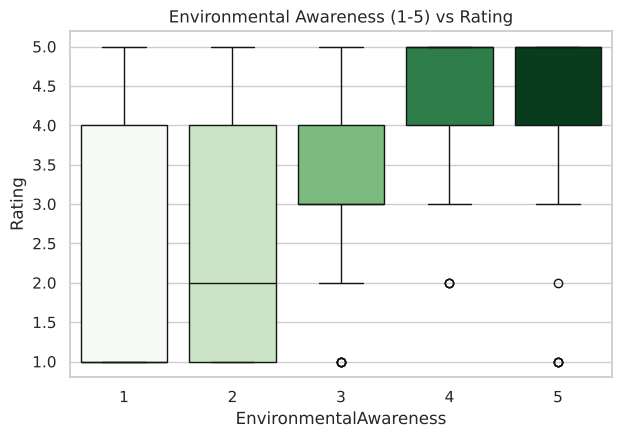

In [13]:
# Location vs Rating (retained from the original notebook)
plt.figure(figsize=(7, 4.5))
sns.boxplot(x="Location", y="Rating", hue="Location", data=df, palette="Set2", legend=False)
plt.title("Sustainability Rating by Location")
plt.show()

# EnvironmentalAwareness (ordinal 1-5) vs Rating
plt.figure(figsize=(7, 4.5))
sns.boxplot(x="EnvironmentalAwareness", y="Rating", hue="EnvironmentalAwareness", data=df, palette="Greens", legend=False)
plt.title("Environmental Awareness (1-5) vs Rating")
plt.show()

### 4.4 Numerical feature distributions

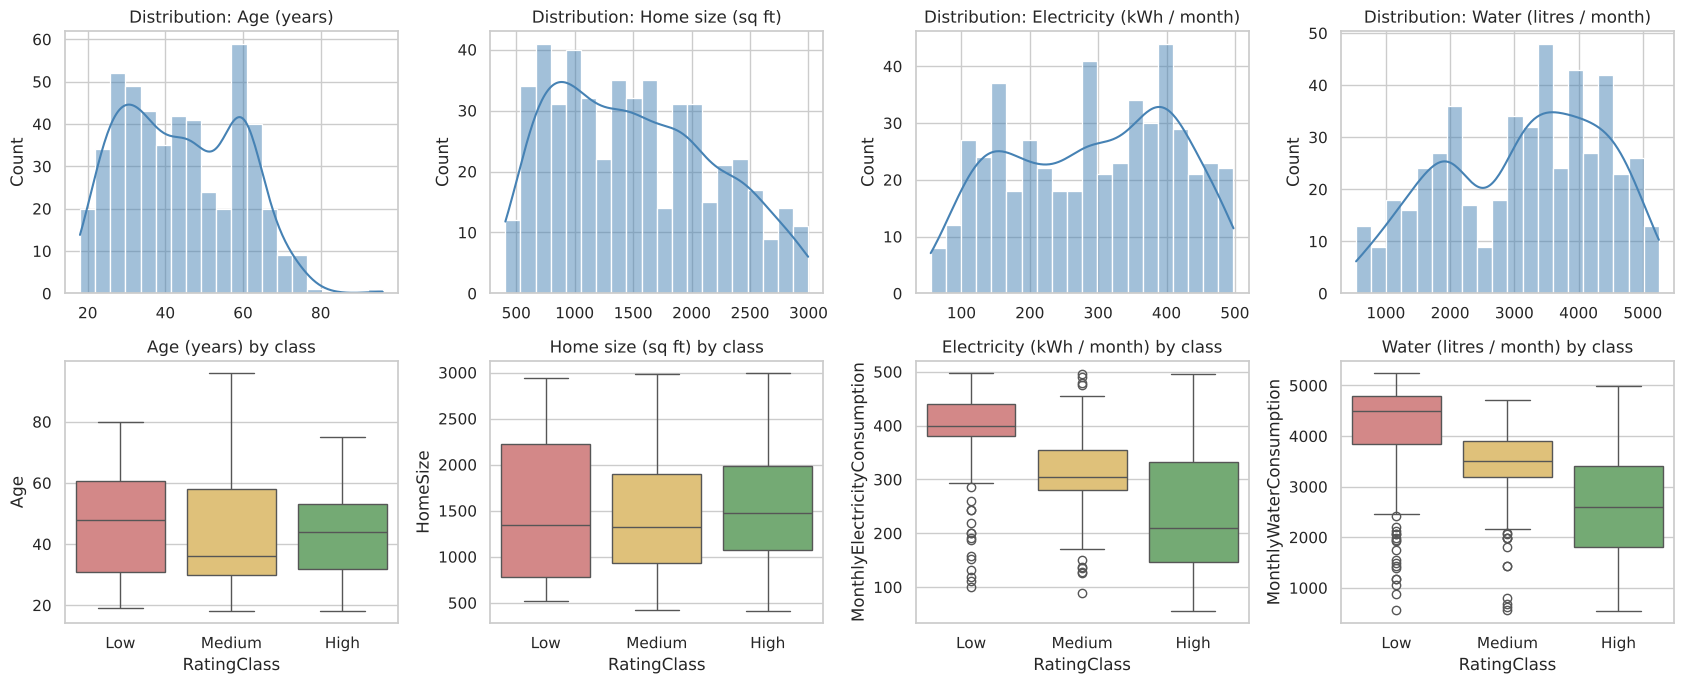

In [14]:
num_labels = {"Age": "Age (years)", "HomeSize": "Home size (sq ft)",
              "MonthlyElectricityConsumption": "Electricity (kWh / month)",
              "MonthlyWaterConsumption": "Water (litres / month)"}
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for j, (col, label) in enumerate(num_labels.items()):
    sns.histplot(df[col], bins=20, kde=True, color="steelblue", ax=axes[0, j])
    axes[0, j].set_title(f"Distribution: {label}"); axes[0, j].set_xlabel("")
    sns.boxplot(x="RatingClass", y=col, data=df, order=CLASS_ORDER, hue="RatingClass", hue_order=CLASS_ORDER,
                palette=class_colors, legend=False, ax=axes[1, j])
    axes[1, j].set_title(f"{label} by class")
plt.tight_layout()
plt.show()

### 4.5 Correlation heatmap

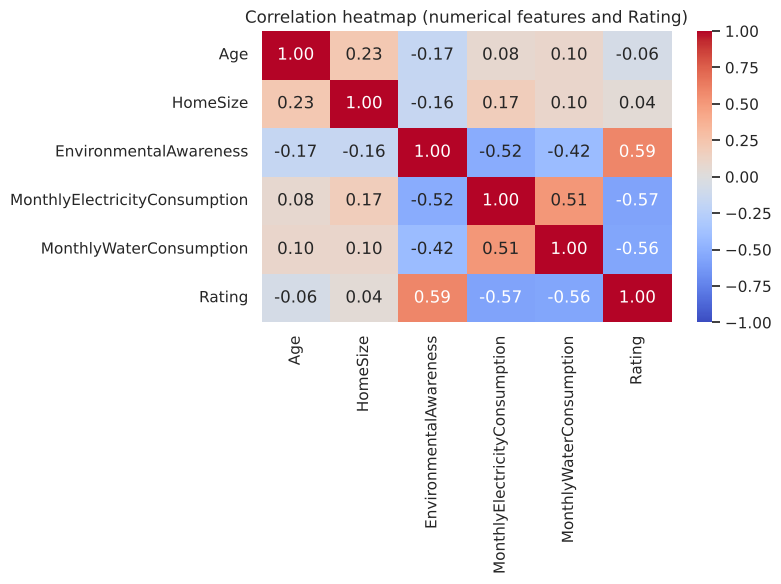

In [15]:
# Numerical features + Rating. This is for EXPLORATION only: Rating is the target, not a model input.
corr_cols = numeric_features + ["Rating"]
plt.figure(figsize=(8, 6))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, cbar=True)
plt.title("Correlation heatmap (numerical features and Rating)")
plt.tight_layout()
plt.show()

**Interpretation (association only):** higher electricity and water use are associated with *lower* ratings, and higher environmental awareness with *higher* ratings. Age and home size show almost no linear relationship with the rating. Correlation describes how variables move together in this sample; it does **not** show that one causes the other. Note that Pearson correlation only captures linear relationships between numbers and ignores the categorical features entirely.

## 5. Train/test split and preprocessing pipeline

**One stratified 80:20 split** is made with a fixed `random_state`. The split happens **before** any preprocessing is fitted, so the scaler, imputers and encoder only ever learn from training data (no data leakage). The test set is kept untouched until the final evaluation in Section 7.

In [16]:
X_train, X_test, y_train, y_test, rating_train, rating_test = train_test_split(
    X, y_class, y_rating, test_size=0.2, stratify=y_class, random_state=RANDOM_STATE)

print("Train:", X_train.shape, "| Test:", X_test.shape)
summary = pd.DataFrame({"train_%": (y_train.value_counts(normalize=True) * 100).round(1),
                        "test_%": (y_test.value_counts(normalize=True) * 100).round(1),
                        "train_n": y_train.value_counts(), "test_n": y_test.value_counts()}).reindex(CLASS_ORDER)
display(summary)

Train: (399, 17) | Test: (100, 17)


,train_%,test_%,train_n,test_n
RatingClass,,,,
Low,26.3,26.0,105,26
Medium,20.3,20.0,81,20
High,53.4,54.0,213,54


In [17]:
def build_preprocessor():
    # Numerical: median imputation -> standardisation.  Categorical: most-frequent imputation -> one-hot.
    numeric_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                             ("scaler", StandardScaler())])
    categorical_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                 ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([("num", numeric_pipe, numeric_features),
                              ("cat", categorical_pipe, categorical_features)])

# Quick look at what the preprocessor produces (fitted on TRAIN only)
_demo = build_preprocessor().fit(X_train)
print("Transformed training matrix shape:", _demo.transform(X_train).shape)
print("Example output feature names:", list(_demo.get_feature_names_out()[:8]), "...")

Transformed training matrix shape: (399, 47)
Example output feature names: ['num__Age', 'num__HomeSize', 'num__EnvironmentalAwareness', 'num__MonthlyElectricityConsumption', 'num__MonthlyWaterConsumption', 'cat__Location_Rural', 'cat__Location_Suburban', 'cat__Location_Urban'] ...


Because there are no truly missing values in this file, the imputers do not change anything here; they are included so the pipeline would still work on incomplete data later. Every model below is wrapped as `Pipeline([("preprocess", ...), ("model", ...)])`, so each cross-validation fold re-fits the preprocessing on that fold's training part only.

## 6. Model comparison with stratified cross-validation (training data only)

In [18]:
models = {
    "Dummy (most frequent)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression":   LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree":         DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest":         RandomForestClassifier(random_state=RANDOM_STATE),
}

def make_pipeline(estimator):
    return Pipeline([("preprocess", build_preprocessor()), ("model", estimator)])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
# zero_division=0 keeps the Dummy baseline (which never predicts Low/Medium) from raising warnings
scoring = {"accuracy": "accuracy",
           "precision_macro": make_scorer(precision_score, average="macro", zero_division=0),
           "recall_macro": make_scorer(recall_score, average="macro", zero_division=0),
           "f1_macro": make_scorer(f1_score, average="macro", zero_division=0)}

cv_rows, cv_detail = [], {}
for name, est in models.items():
    res = cross_validate(make_pipeline(est), X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    cv_detail[name] = res
    row = {"Model": name}
    for m in scoring:
        row[m + "_mean"] = res["test_" + m].mean()
        row[m + "_std"] = res["test_" + m].std()
    cv_rows.append(row)

cv_results = pd.DataFrame(cv_rows).set_index("Model")
display(cv_results[[c for c in cv_results.columns if c.endswith("_mean")]].round(4))
print("(Standard deviations across the 5 folds)")
display(cv_results[[c for c in cv_results.columns if c.endswith("_std")]].round(4))

,accuracy_mean,precision_macro_mean,recall_macro_mean,f1_macro_mean
Model,,,,
Dummy (most frequent),0.5338,0.1779,0.3333,0.2320
Logistic Regression,0.8018,0.7666,0.7649,0.7633
Decision Tree,0.7494,0.7214,0.7181,0.7104
Random Forest,0.8319,0.8633,0.7650,0.7910


(Standard deviations across the 5 folds)


,accuracy_std,precision_macro_std,recall_macro_std,f1_macro_std
Model,,,,
Dummy (most frequent),0.0050,0.0017,0.0000,0.0014
Logistic Regression,0.0606,0.0711,0.0711,0.0704
Decision Tree,0.0395,0.0478,0.0609,0.0535
Random Forest,0.0566,0.0366,0.0855,0.0778


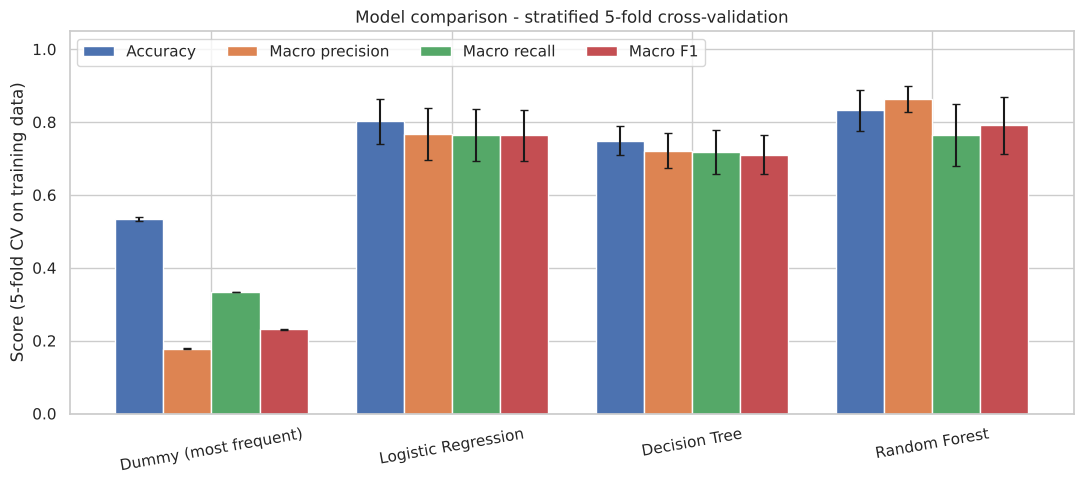

In [19]:
# Model comparison chart: mean CV score with +/- 1 std error bars
metric_names = {"accuracy": "Accuracy", "precision_macro": "Macro precision",
                "recall_macro": "Macro recall", "f1_macro": "Macro F1"}
plot_models = list(cv_results.index)
x = np.arange(len(plot_models))
width = 0.2

fig, ax = plt.subplots(figsize=(11, 5))
for i, (m, label) in enumerate(metric_names.items()):
    ax.bar(x + (i - 1.5) * width, cv_results[m + "_mean"], width, yerr=cv_results[m + "_std"],
           capsize=3, label=label)
ax.set_xticks(x); ax.set_xticklabels(plot_models, rotation=10)
ax.set_ylim(0, 1.05); ax.set_ylabel("Score (5-fold CV on training data)")
ax.set_title("Model comparison - stratified 5-fold cross-validation")
ax.legend(ncol=4, loc="upper left")
plt.tight_layout()
plt.show()

In [20]:
# Choose the strongest REAL model (the dummy is only a baseline) by mean macro F1 in cross-validation
real_models = cv_results.drop(index="Dummy (most frequent)")
best_name = real_models["f1_macro_mean"].idxmax()
print("Strongest candidate by CV macro F1:", best_name)
print(f"CV macro F1 = {real_models.loc[best_name, 'f1_macro_mean']:.4f} "
      f"(dummy baseline = {cv_results.loc['Dummy (most frequent)', 'f1_macro_mean']:.4f})")

Strongest candidate by CV macro F1: Random Forest
CV macro F1 = 0.7910 (dummy baseline = 0.2320)


**How to read this:** the dummy baseline shows what "no learning" achieves, so any real model must clearly beat it. Macro precision/recall/F1 average the three classes equally, so the small *Medium* class counts as much as *High*. The models are ranked on **macro F1** because of the class imbalance. Differences between models that are smaller than the fold-to-fold standard deviation should not be over-interpreted.

### Is the rating rule-like? (training data only)

In [21]:
# Exploratory probe: how well do very shallow decision trees do? Uses TRAINING data only.
probe_rows = []
for depth in [1, 2, 3, 4, 5, 6, 8, None]:
    res = cross_validate(make_pipeline(DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE)),
                         X_train, y_train, cv=cv, scoring={"acc": "accuracy", "f1": scoring["f1_macro"]})
    probe_rows.append({"max_depth": "None" if depth is None else depth,
                       "CV accuracy": res["test_acc"].mean(), "CV macro F1": res["test_f1"].mean()})
display(pd.DataFrame(probe_rows).round(4))

,max_depth,CV accuracy,CV macro F1
0,1,0.6365,0.4666
1,2,0.7216,0.7055
2,3,0.7543,0.7146
3,4,0.7267,0.6809
4,5,0.7593,0.7175
5,6,0.7568,0.7144
6,8,0.7594,0.7213
7,None,0.7494,0.7104


If the ratings were produced by a *simple, exact* rule on these 17 features, a small tree would reach near-perfect scores. That does not happen here, so the rating is **not** a simple deterministic function of these features alone (it may depend on information not in the file, or on noise). This is a statement about what the models can recover, not about how the data was generated.

## 7. Hyperparameter tuning and final evaluation on the untouched test set

Only the **strongest candidate** from Section 6 is tuned, using `GridSearchCV` with the same stratified 5-fold CV and **macro F1** as the scoring metric, on the training data only. The test set is used **once**, after tuning, to estimate real-world performance.

In [22]:
param_grids = {
    "Logistic Regression": {"model__C": [0.01, 0.1, 1, 10, 100]},
    "Decision Tree": {"model__max_depth": [3, 5, 8, 12, None],
                      "model__min_samples_split": [2, 5, 10],
                      "model__min_samples_leaf": [1, 2, 4],
                      "model__criterion": ["gini", "entropy"]},
    "Random Forest": {"model__n_estimators": [100, 200, 300],
                      "model__max_depth": [None, 5, 10, 15],
                      "model__min_samples_split": [2, 5, 10],
                      "model__min_samples_leaf": [1, 2, 4]},
}

grid = GridSearchCV(make_pipeline(models[best_name]), param_grids[best_name],
                    cv=cv, scoring=scoring["f1_macro"], n_jobs=1, refit=True)
grid.fit(X_train, y_train)

print("Tuned model          :", best_name)
print("Best parameters      :", grid.best_params_)
print(f"Best CV macro F1     : {grid.best_score_:.4f}   (default settings: {real_models.loc[best_name, 'f1_macro_mean']:.4f})")
final_model = grid.best_estimator_

Tuned model          : Random Forest
Best parameters      : {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 300}
Best CV macro F1     : 0.8064   (default settings: 0.7910)


In [23]:
# Before-vs-after tuning, measured the same way (CV on training data)
tuned_cv = cross_validate(final_model, X_train, y_train, cv=cv, scoring=scoring)
tune_cmp = pd.DataFrame({
    "Default (CV)": {m: cv_results.loc[best_name, m + "_mean"] for m in scoring},
    "Tuned (CV)":   {m: tuned_cv["test_" + m].mean() for m in scoring}}).round(4)
display(tune_cmp)

,Default (CV),Tuned (CV)
accuracy,0.8319,0.8444
precision_macro,0.8633,0.8849
recall_macro,0.7650,0.7770
f1_macro,0.7910,0.8064


In [24]:
# ---- FINAL evaluation on the untouched test set (used once) ----
y_pred = final_model.predict(X_test)

test_metrics = pd.Series({
    "Accuracy": accuracy_score(y_test, y_pred),
    "Macro precision": precision_score(y_test, y_pred, average="macro", zero_division=0),
    "Macro recall": recall_score(y_test, y_pred, average="macro", zero_division=0),
    "Macro F1": f1_score(y_test, y_pred, average="macro", zero_division=0)}, name="Test set")
dummy_test = make_pipeline(models["Dummy (most frequent)"]).fit(X_train, y_train).predict(X_test)
test_metrics_dummy = pd.Series({
    "Accuracy": accuracy_score(y_test, dummy_test),
    "Macro precision": precision_score(y_test, dummy_test, average="macro", zero_division=0),
    "Macro recall": recall_score(y_test, dummy_test, average="macro", zero_division=0),
    "Macro F1": f1_score(y_test, dummy_test, average="macro", zero_division=0)}, name="Dummy baseline (test)")

print(f"Final model: tuned {best_name}  | test set size = {len(y_test)}")
display(pd.concat([test_metrics, test_metrics_dummy], axis=1).round(4))

print("Complete classification report (test set):\n")
print(classification_report(y_test, y_pred, labels=CLASS_ORDER, digits=3, zero_division=0))

Final model: tuned Random Forest  | test set size = 100


,Test set,Dummy baseline (test)
Accuracy,0.8200,0.5400
Macro precision,0.8845,0.1800
Macro recall,0.7594,0.3333
Macro F1,0.8011,0.2338


Complete classification report (test set):

              precision    recall  f1-score   support

         Low      0.889     0.615     0.727        26
      Medium      1.000     0.700     0.824        20
        High      0.765     0.963     0.852        54

    accuracy                          0.820       100
   macro avg      0.885     0.759     0.801       100
weighted avg      0.844     0.820     0.814       100



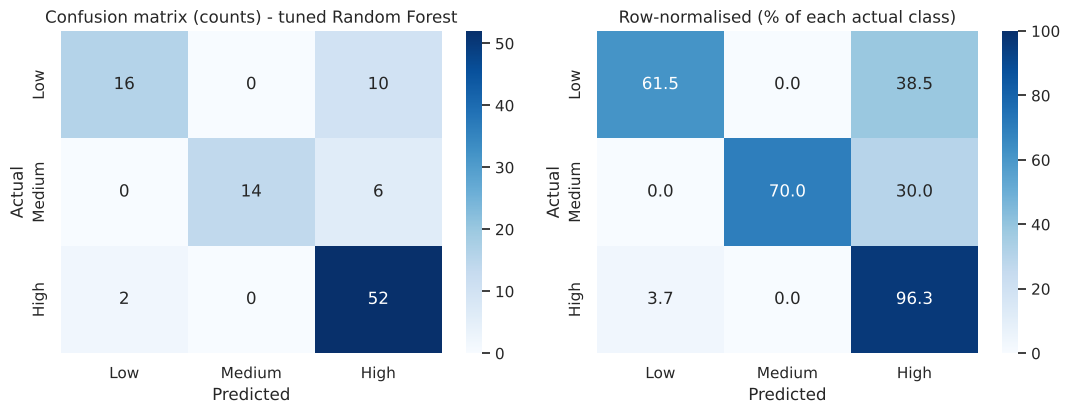

In [25]:
# Confusion matrix (retained and corrected: fixed class order, counts + row-normalised)
cm = confusion_matrix(y_test, y_pred, labels=CLASS_ORDER)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_ORDER, yticklabels=CLASS_ORDER, ax=axes[0])
axes[0].set_title(f"Confusion matrix (counts) - tuned {best_name}")
sns.heatmap(cm_pct, annot=True, fmt=".1f", cmap="Blues", xticklabels=CLASS_ORDER, yticklabels=CLASS_ORDER,
            vmin=0, vmax=100, ax=axes[1])
axes[1].set_title("Row-normalised (% of each actual class)")
for ax in axes:
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

**Interpretation** *(numbers refer to the run saved in this notebook; they may shift slightly with other library versions)*

* Of the 100 test participants, the model got **16/26 Low**, **14/20 Medium** and **52/54 High** right.
* There are 18 mistakes: 16 of them are participants wrongly predicted as **High** (10 Low and 6 Medium), and 2 High participants were predicted Low. There is no Low↔Medium confusion at all.
* So the model leans towards the majority class (High): very high recall for High, but lower precision for it, while Low and Medium have high precision but lower recall. In plain words, it is more likely to *over-rate* a participant than to under-rate one.
* The test set is small (100 rows), so each single participant moves a class recall by 4–5 percentage points. Treat these figures as rough estimates.

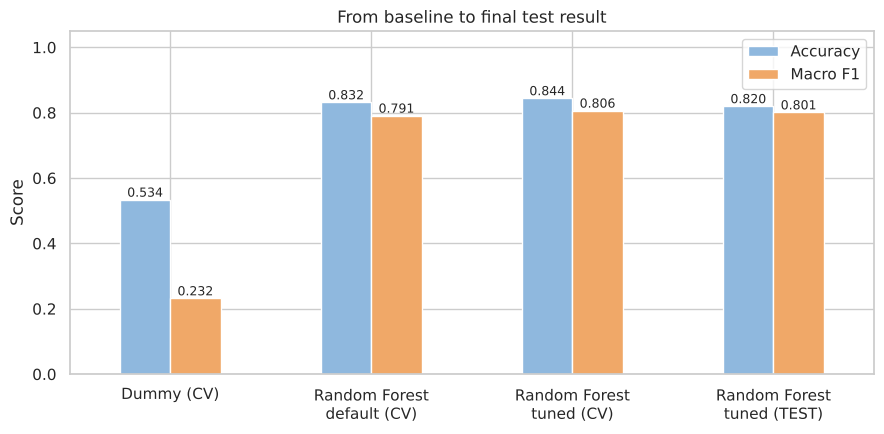

In [26]:
# Overall summary chart: dummy vs default (CV) vs tuned (CV) vs tuned (test), macro F1 and accuracy
summary_df = pd.DataFrame({
    "Accuracy": [cv_results.loc["Dummy (most frequent)", "accuracy_mean"], cv_results.loc[best_name, "accuracy_mean"],
                 tuned_cv["test_accuracy"].mean(), test_metrics["Accuracy"]],
    "Macro F1": [cv_results.loc["Dummy (most frequent)", "f1_macro_mean"], cv_results.loc[best_name, "f1_macro_mean"],
                 tuned_cv["test_f1_macro"].mean(), test_metrics["Macro F1"]]},
    index=["Dummy (CV)", f"{best_name}\ndefault (CV)", f"{best_name}\ntuned (CV)", f"{best_name}\ntuned (TEST)"])
ax = summary_df.plot(kind="bar", figsize=(9, 4.5), rot=0, color=["#8fb8de", "#f0a868"])
ax.set_ylim(0, 1.05); ax.set_ylabel("Score"); ax.set_title("From baseline to final test result")
for p in ax.patches:
    ax.annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

### Supplementary: group-aware cross-validation (identical profiles kept together)

In the standard stratified CV, two rows with the **same 17 lifestyle answers** can land one in a training fold and one in the validation fold, which can make validation scores look better than they would be for genuinely new profiles. Here every distinct 17-feature profile is given a **group id**, and `StratifiedGroupKFold` keeps each group entirely inside one fold while keeping class proportions similar. This is a **supplementary check on the training data only**: the primary evaluation above is unchanged and the **test set is not used or re-used** here. The tuned settings were chosen earlier with the standard CV, so the tuned row below is a fair *re-measurement*, not a new tuning.

In [27]:
from sklearn.base import clone

# Group id = one id per distinct 17-feature lifestyle profile (computed on TRAINING rows only)
profile_key = X_train.astype(str).apply("|".join, axis=1)
groups_train = pd.factorize(profile_key)[0]
print("Training rows:", len(X_train), "| distinct profiles (groups):", len(np.unique(groups_train)))

# Use StratifiedGroupKFold where supported; fall back to plain GroupKFold on very old scikit-learn
try:
    from sklearn.model_selection import StratifiedGroupKFold
    group_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    group_cv_name = "StratifiedGroupKFold"
except ImportError:
    from sklearn.model_selection import GroupKFold
    group_cv = GroupKFold(n_splits=5)
    group_cv_name = "GroupKFold (StratifiedGroupKFold not available; no stratification)"
print("Group-aware splitter:", group_cv_name)

# Verify: with group-aware CV no profile is ever in both the training and validation part of a fold.
# For comparison, count how many validation rows have a twin in the training part under the standard CV.
def n_twin_rows(splitter, **kw):
    twins = 0
    for tr_idx, va_idx in splitter.split(X_train, y_train, **kw):
        twins += np.isin(groups_train[va_idx], groups_train[tr_idx]).sum()
    return int(twins)

twins_standard = n_twin_rows(cv)
twins_group = n_twin_rows(group_cv, groups=groups_train)
print(f"Validation rows with an identical profile in the training part - standard CV: {twins_standard} | group-aware CV: {twins_group}")
assert twins_group == 0, "Group-aware CV leaked a profile across folds"

Training rows: 399 | distinct profiles (groups): 374
Group-aware splitter: StratifiedGroupKFold
Validation rows with an identical profile in the training part - standard CV: 46 | group-aware CV: 0


In [28]:
# Same models, same preprocessing, same metrics - only the way folds are made differs
group_models = dict(models)
group_models[f"{best_name} (tuned settings)"] = clone(final_model.named_steps["model"])

rows = []
for name, est in group_models.items():
    pipe = make_pipeline(est)
    res_g = cross_validate(pipe, X_train, y_train, cv=group_cv, groups=groups_train, scoring=scoring, n_jobs=1)
    if name in cv_results.index:
        std_acc, std_f1 = cv_results.loc[name, "accuracy_mean"], cv_results.loc[name, "f1_macro_mean"]
    else:   # tuned model: standard-CV score measured earlier
        std_acc, std_f1 = tuned_cv["test_accuracy"].mean(), tuned_cv["test_f1_macro"].mean()
    rows.append({"Model": name,
                 "Accuracy (standard CV)": std_acc, "Accuracy (group CV)": res_g["test_accuracy"].mean(),
                 "Macro F1 (standard CV)": std_f1, "Macro F1 (group CV)": res_g["test_f1_macro"].mean(),
                 "Macro F1 std (group CV)": res_g["test_f1_macro"].std()})
group_cmp = pd.DataFrame(rows).set_index("Model")
group_cmp["Macro F1 change"] = group_cmp["Macro F1 (group CV)"] - group_cmp["Macro F1 (standard CV)"]
display(group_cmp.round(4))

,Accuracy (standard CV),Accuracy (group CV),Macro F1 (standard CV),Macro F1 (group CV),Macro F1 std (group CV),Macro F1 change
Model,,,,,,
Dummy (most frequent),0.5338,0.5338,0.2320,0.2320,0.0009,0.0000
Logistic Regression,0.8018,0.7769,0.7633,0.7417,0.0175,-0.0216
Decision Tree,0.7494,0.7343,0.7104,0.7052,0.0165,-0.0051
Random Forest,0.8319,0.8172,0.7910,0.7812,0.0391,-0.0098
Random Forest (tuned settings),0.8444,0.8222,0.8064,0.7876,0.0359,-0.0188


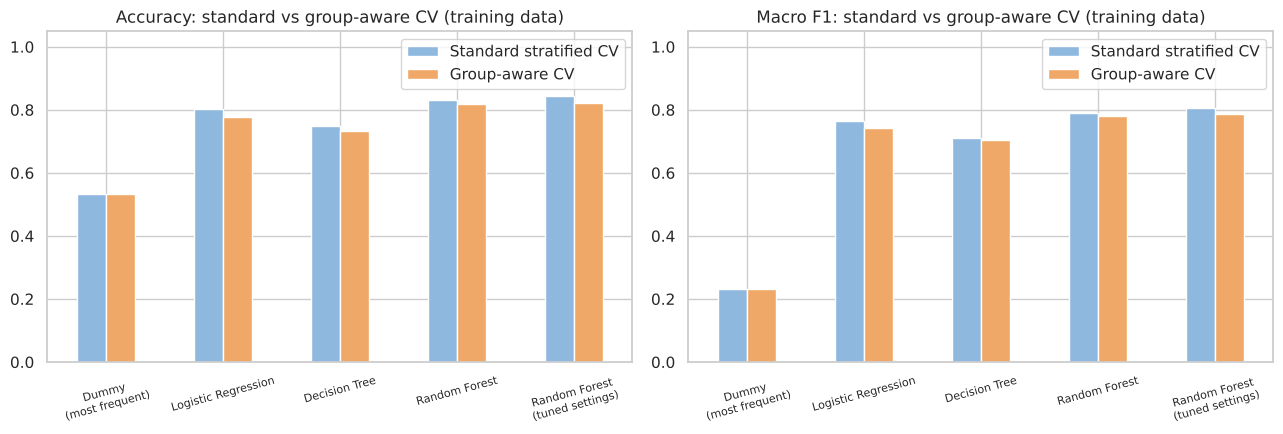

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, metric in zip(axes, ["Accuracy", "Macro F1"]):
    pd.DataFrame({"Standard stratified CV": group_cmp[f"{metric} (standard CV)"],
                  "Group-aware CV": group_cmp[f"{metric} (group CV)"]}).plot(
        kind="bar", ax=ax, rot=15, color=["#8fb8de", "#f0a868"])
    ax.set_ylim(0, 1.05); ax.set_title(f"{metric}: standard vs group-aware CV (training data)")
    ax.set_xlabel(""); ax.set_xticklabels([t.get_text().replace(" (", "\n(") for t in ax.get_xticklabels()], fontsize=8)
plt.tight_layout()
plt.show()

**Interpretation** *(numbers from the run saved in this notebook)*:
* Under the standard stratified CV, **46 validation rows** (summed over the 5 folds, out of 399 training rows) had an identical 17-feature profile in the training part of their fold. Under group-aware CV that number is **0**, as the cell asserts.
* Macro F1 is a little lower with group-aware CV for every real model (about 0.5 to 2.2 points; for the default Random Forest 0.791 → 0.781, for the tuned settings 0.806 → 0.788). Accuracy drops by about 1.5 to 2.5 points for the same models. The dummy baseline is unchanged.
* The ranking of the models does not change (Random Forest > Logistic Regression > Decision Tree > Dummy), and the drops are of a similar size to the fold-to-fold standard deviation under group CV (about 0.02–0.04; for Logistic Regression the drop is slightly larger), so this is **mild** evidence that repeated profiles inflate the standard CV scores a little. It does not change the primary results or the model choice.
* Group CV was run on training data only; the test set was not touched.

## 8. Model interpretation

### 8.1 Predicted class probabilities

First 10 test participants (row labels = original DataFrame index):


,Actual,Predicted,P(Low),P(Medium),P(High),Max predicted class probability (uncalibrated),Correct
230,Low,High,0.243,0.223,0.533,0.533,False
451,Low,Low,0.430,0.203,0.367,0.430,True
461,High,High,0.143,0.100,0.757,0.757,True
215,Medium,Medium,0.003,0.993,0.003,0.993,True
321,High,High,0.043,0.110,0.847,0.847,True
45,High,High,0.000,0.003,0.997,0.997,True
104,High,High,0.000,0.003,0.997,0.997,True
192,Low,Low,1.000,0.000,0.000,1.000,True
429,High,High,0.227,0.267,0.507,0.507,True
234,Medium,High,0.100,0.410,0.490,0.490,False


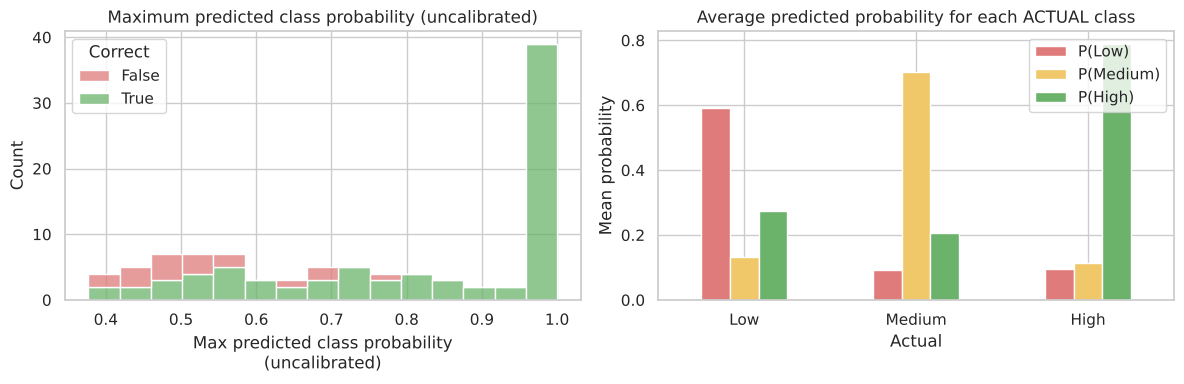

Mean max predicted class probability (uncalibrated) when correct: 0.821 | when wrong: 0.524


In [30]:
if hasattr(final_model, "predict_proba"):
    proba = final_model.predict_proba(X_test)
    classes = list(final_model.classes_)
    proba_df = pd.DataFrame(proba, columns=[f"P({c})" for c in classes], index=X_test.index)[[f"P({c})" for c in CLASS_ORDER]]
    proba_df.insert(0, "Actual", y_test)
    proba_df.insert(1, "Predicted", y_pred)
    MAXP = "Max predicted class probability (uncalibrated)"
    proba_df[MAXP] = proba.max(axis=1)
    proba_df["Correct"] = proba_df["Actual"] == proba_df["Predicted"]

    print("First 10 test participants (row labels = original DataFrame index):")
    display(proba_df.head(10).round(3))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.histplot(data=proba_df, x=MAXP, hue="Correct", bins=15, multiple="stack", ax=axes[0],
                 palette={True: "#6bb36b", False: "#e07b7b"})
    axes[0].set_title("Maximum predicted class probability (uncalibrated)")
    axes[0].set_xlabel("Max predicted class probability\n(uncalibrated)")
    proba_df.groupby("Actual")[[f"P({c})" for c in CLASS_ORDER]].mean().reindex(CLASS_ORDER).plot(
        kind="bar", ax=axes[1], rot=0, color=[class_colors[c] for c in CLASS_ORDER])
    axes[1].set_title("Average predicted probability for each ACTUAL class")
    axes[1].set_ylabel("Mean probability")
    plt.tight_layout()
    plt.show()
    print(f"Mean max predicted class probability (uncalibrated) when correct: {proba_df.loc[proba_df.Correct, MAXP].mean():.3f} | "
          f"when wrong: {proba_df.loc[~proba_df.Correct, MAXP].mean():.3f}")
else:
    print(f"{best_name} does not provide predicted probabilities.")

**Interpretation:** the Random Forest probabilities are the share of trees voting for each class. The **maximum predicted class probability (uncalibrated)** is clearly higher on average for correct predictions than for wrong ones, and wrong predictions tend to sit near 0.5, so it is a useful *relative* signal. But it is **not a calibrated probability and not a confidence guarantee**: a value of 0.8 does not mean an 80% chance of being right. Predictions with a low maximum probability deserve the most caution.

### 8.2 Feature importance (model-based)

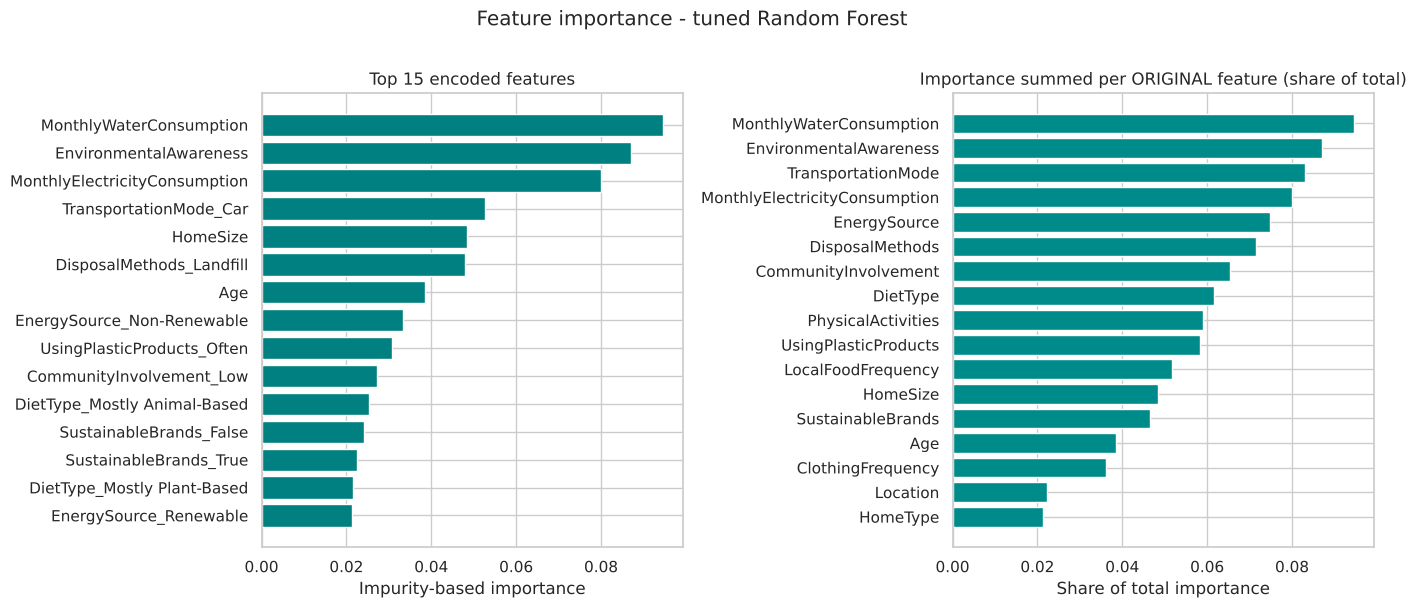

In [31]:
# Model-native importance, summed back to the ORIGINAL 17 features
fitted_pre = final_model.named_steps["preprocess"]
fitted_est = final_model.named_steps["model"]
out_names = list(fitted_pre.get_feature_names_out())

if hasattr(fitted_est, "feature_importances_"):
    raw_imp = fitted_est.feature_importances_
    imp_label = "Impurity-based importance"
elif hasattr(fitted_est, "coef_"):
    raw_imp = np.abs(fitted_est.coef_).mean(axis=0)
    imp_label = "Mean |coefficient| (standardised inputs)"
else:
    raw_imp = None

if raw_imp is not None:
    def original_feature(name):
        if name.startswith("num__"):
            return name[len("num__"):]
        body = name[len("cat__"):]
        for col in sorted(categorical_features, key=len, reverse=True):
            if body.startswith(col + "_"):
                return col
        return body

    imp_encoded = pd.Series(raw_imp, index=out_names).sort_values(ascending=False)
    imp_original = pd.Series(raw_imp, index=[original_feature(n) for n in out_names]).groupby(level=0).sum()
    imp_original = (imp_original / imp_original.sum()).sort_values(ascending=True)

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    top_enc = imp_encoded.head(15).iloc[::-1]
    axes[0].barh([n.split("__", 1)[1] for n in top_enc.index], top_enc.values, color="teal")
    axes[0].set_title("Top 15 encoded features"); axes[0].set_xlabel(imp_label)
    axes[1].barh(imp_original.index, imp_original.values, color="darkcyan")
    axes[1].set_title("Importance summed per ORIGINAL feature (share of total)")
    axes[1].set_xlabel("Share of total importance")
    plt.suptitle(f"Feature importance - tuned {best_name}", y=1.01)
    plt.tight_layout()
    plt.show()

Model-based importance can be **biased**: impurity-based importance in tree models tends to favour features with many distinct values (for example the continuous ones), and one-hot encoding splits a single feature's importance across several columns (which is why it is also summed back per original feature). It shows what the model *used*, not what *causes* a rating. Permutation importance on held-out data (next) is a more reliable cross-check.

### 8.3 Permutation importance on the held-out test set

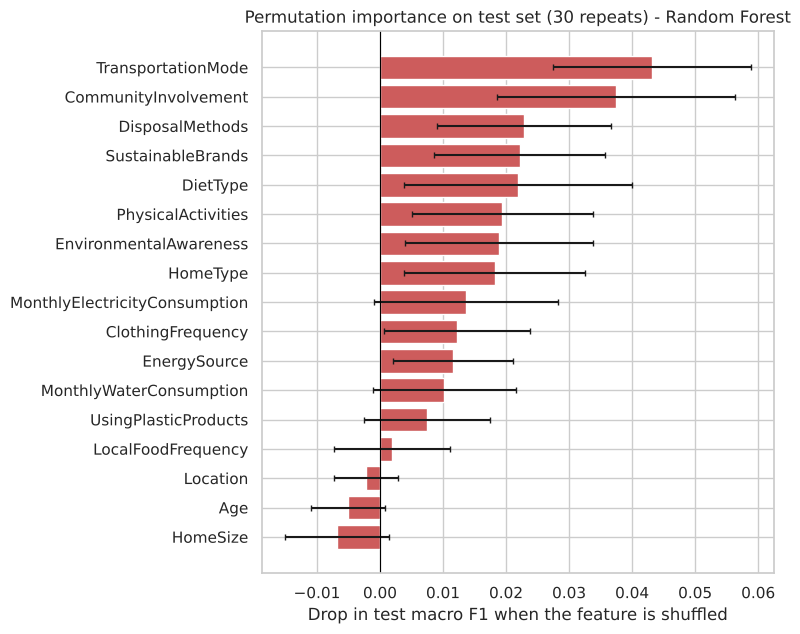

,feature,mean_drop,std
0,TransportationMode,0.0431,0.0157
1,CommunityInvolvement,0.0375,0.0189
2,DisposalMethods,0.0229,0.0138
3,SustainableBrands,0.0221,0.0135
4,DietType,0.0219,0.0181
5,PhysicalActivities,0.0194,0.0143
6,EnvironmentalAwareness,0.0189,0.0148
7,HomeType,0.0182,0.0143


In [32]:
# Shuffle ONE original feature at a time in the test set and measure how much macro F1 drops.
# The whole pipeline is used, so importance is reported per ORIGINAL feature (not per one-hot column).
perm = permutation_importance(final_model, X_test, y_test, scoring=scoring["f1_macro"],
                              n_repeats=30, random_state=RANDOM_STATE, n_jobs=1)
perm_df = pd.DataFrame({"feature": X_test.columns, "mean_drop": perm.importances_mean,
                        "std": perm.importances_std}).sort_values("mean_drop", ascending=True)

plt.figure(figsize=(8, 6.5))
plt.barh(perm_df["feature"], perm_df["mean_drop"], xerr=perm_df["std"], color="indianred", capsize=2)
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("Drop in test macro F1 when the feature is shuffled")
plt.title(f"Permutation importance on test set (30 repeats) - {best_name}")
plt.tight_layout()
plt.show()

display(perm_df.sort_values("mean_drop", ascending=False).head(8).round(4).reset_index(drop=True))

**Interpretation:**
* Shuffling `TransportationMode` and `CommunityInvolvement` produced the largest drops in test macro F1, followed by `DisposalMethods`, `SustainableBrands` and `DietType`. `Age`, `HomeSize` and `Location` show no detectable benefit (drops around or below zero).
* The error bars (±1 std over 30 shuffles) are of similar size to many of the differences, and the test set has only 100 rows, so the **ranking in the middle is not stable** — only the broad split between "clearly used" and "not used" is trustworthy.
* The two views differ: impurity-based importance spreads weight across many features (water use, awareness, transport, electricity) while permutation importance ranks others higher. Features such as diet, energy source and awareness are strongly related to the rating on their own (Section 4), yet score modestly here. A plausible reason is that several features carry overlapping information, so shuffling one is partly compensated by the others — this is a hypothesis, not something verified in this notebook.
* Importance describes what the **model relies on**, not what causes a rating.

## 9. Supplementary: Linear Regression experiment (numeric Rating 1–5)

This section is a **separate, supplementary** experiment kept from the original notebook. It predicts the numeric `Rating` (1–5) instead of the class, so it is evaluated with **regression metrics only (RMSE, MAE, R²)** — never accuracy or F1. It uses the **same train/test split** and the **same 17 features and preprocessing** (scaling + one-hot encoding fitted on training data only). Its numbers are **not comparable** with the classification scores above.

In [33]:
reg_pipe = Pipeline([("preprocess", build_preprocessor()), ("model", LinearRegression())])
reg_pipe.fit(X_train, rating_train)
rating_pred = reg_pipe.predict(X_test)

dummy_reg = Pipeline([("preprocess", build_preprocessor()), ("model", DummyRegressor(strategy="mean"))]).fit(X_train, rating_train)
rating_pred_dummy = dummy_reg.predict(X_test)

def reg_metrics(y_true, y_hat):
    return {"RMSE": float(np.sqrt(mean_squared_error(y_true, y_hat))),
            "MAE": float(mean_absolute_error(y_true, y_hat)),
            "R²": float(r2_score(y_true, y_hat))}

reg_cv = cross_validate(Pipeline([("preprocess", build_preprocessor()), ("model", LinearRegression())]),
                        X_train, rating_train, cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
                        scoring={"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"})
print("5-fold CV on training data -> RMSE: %.3f | MAE: %.3f | R²: %.3f" % (
      -reg_cv["test_rmse"].mean(), -reg_cv["test_mae"].mean(), reg_cv["test_r2"].mean()))

reg_table = pd.DataFrame({"Linear Regression (test)": reg_metrics(rating_test, rating_pred),
                          "Mean-predictor baseline (test)": reg_metrics(rating_test, rating_pred_dummy)}).round(4)
display(reg_table)

5-fold CV on training data -> RMSE: 0.878 | MAE: 0.630 | R²: 0.661


,Linear Regression (test),Mean-predictor baseline (test)
RMSE,0.9609,1.4112
MAE,0.7253,1.2363
R²,0.5358,-0.0012


**Interpretation:** on the test set Linear Regression reaches RMSE ≈ 0.96, MAE ≈ 0.73 and R² ≈ 0.54, compared with RMSE ≈ 1.41, MAE ≈ 1.24 and R² ≈ 0 for always predicting the average rating. So it explains roughly half of the variation in the 1–5 rating, and typical errors are under one rating point. Caveats: the rating is an *ordered* scale, and treating it as a continuous number is an assumption; predictions are not limited to 1–5 or to whole numbers; and these metrics must **not** be compared with the classification accuracy/F1 above.

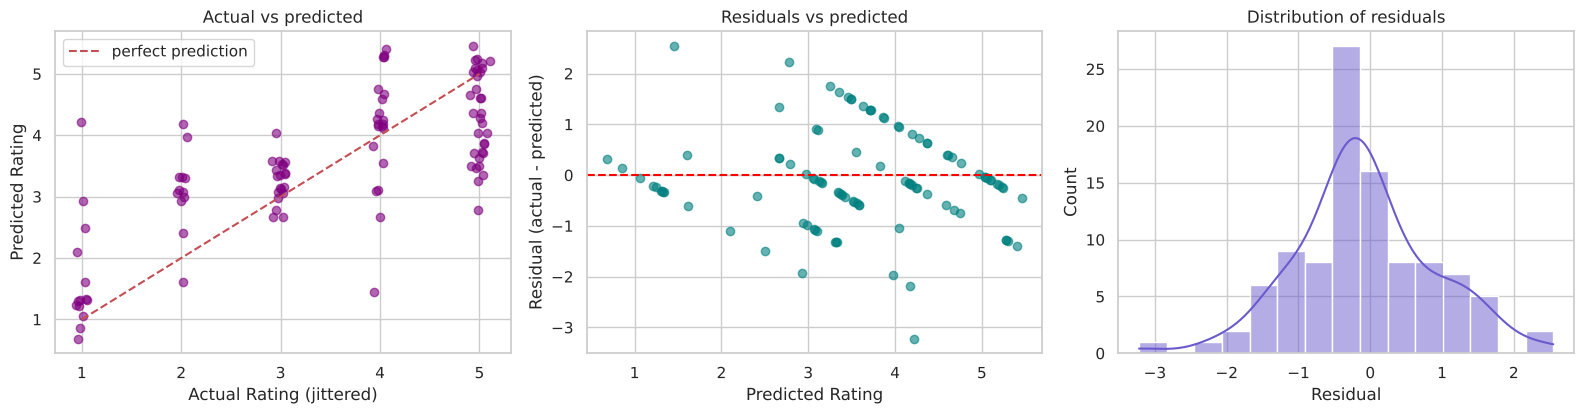

In [34]:
residuals = rating_test.values - rating_pred
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))

# Actual vs predicted (this is what the original notebook labelled 'Residuals plot')
jitter = np.random.default_rng(RANDOM_STATE).normal(0, 0.05, len(rating_test))
axes[0].scatter(rating_test.values + jitter, rating_pred, alpha=0.6, color="purple")
axes[0].plot([1, 5], [1, 5], "r--", label="perfect prediction")
axes[0].set_xlabel("Actual Rating (jittered)"); axes[0].set_ylabel("Predicted Rating")
axes[0].set_title("Actual vs predicted"); axes[0].legend()

# True residual plot
axes[1].scatter(rating_pred, residuals, alpha=0.6, color="teal")
axes[1].axhline(0, color="red", ls="--")
axes[1].set_xlabel("Predicted Rating"); axes[1].set_ylabel("Residual (actual - predicted)")
axes[1].set_title("Residuals vs predicted")

sns.histplot(residuals, bins=15, kde=True, color="slateblue", ax=axes[2])
axes[2].set_title("Distribution of residuals"); axes[2].set_xlabel("Residual")
plt.tight_layout()
plt.show()

## 10. Limitations and summary

In [35]:
# Do test rows that have an IDENTICAL feature profile in the training set score differently from the rest?
train_profiles = set(map(tuple, X_train.astype(str).values))
has_twin = np.array([tuple(r) in train_profiles for r in X_test.astype(str).values])
correct = (np.asarray(y_pred) == y_test.values)

print(f"Test rows with an identical feature profile in the training set: {has_twin.sum()} of {len(has_twin)}")
if has_twin.sum():
    print(f"  accuracy on those rows : {correct[has_twin].mean():.3f}")
if (~has_twin).sum():
    print(f"  accuracy on the others : {correct[~has_twin].mean():.3f}  (n = {(~has_twin).sum()})")

Test rows with an identical feature profile in the training set: 13 of 100
  accuracy on those rows : 1.000
  accuracy on the others : 0.793  (n = 87)


### Limitations — please read before using any result
* **Small dataset.** 499 rows in total and only 100 in the test set. Fold-to-fold standard deviations in cross-validation are around 0.04–0.09, so differences of a few percentage points between models are within noise.
* **Repeated profiles.** 41 extra rows repeat an earlier row's 17 lifestyle answers (40 profiles occur more than once, 81 rows involved; 39 of those extra rows are also identical in `Gender` and `Rating`). They were kept because the data must not be altered. Group-aware CV (Section 7) lowered macro F1 by roughly 0.5–2 points, and test rows with an identical profile in the training set were predicted correctly every time, versus a clearly lower accuracy on the others (see the cell above). The headline test score is therefore probably somewhat **optimistic for genuinely new people**.
* **Unknown provenance.** We do not know how the data was collected or how the `Rating` was assigned. The ratings look fairly regular, but we make no claim about whether they were self-reported, scored by a rule, or generated.
* **The Rating is a given label, not a measurement.** The classifier predicts the dataset's sustainability *rating category* from lifestyle answers. It does **not** calculate carbon emissions or any real environmental impact.
* **Association, not causation.** Relationships found by EDA, feature importance and permutation importance show what goes together in this sample. They do not show that changing a habit would change a rating or real-world impact.
* **Class imbalance.** High is about 54% of the data; the model leans towards predicting High.
* **No external validation.** Everything was evaluated on one dataset; performance on other populations is unknown. Fairness across groups was not assessed (`Gender` was deliberately excluded from the features, but proxies may exist).
* **Tuning on small data.** The tuned cross-validation score is slightly optimistic because the same folds were used to pick the settings.
* **Recommendation engine (Section 11).** Its rules are hand-written heuristics that have **not** been tested with real users or shown to change behaviour or ratings; they are separate from the classifier.

### Summary of classification results *(from the run saved in this notebook)*

| Stage | Accuracy | Macro F1 |
|---|---|---|
| Dummy baseline (CV, train) | 0.534 | 0.232 |
| Decision Tree, default (CV) | 0.749 | 0.710 |
| Logistic Regression, default (CV) | 0.802 | 0.763 |
| Random Forest, default (CV) — strongest candidate | 0.832 | 0.791 |
| Random Forest, tuned (CV) | 0.844 | 0.806 |
| Random Forest, tuned, group-aware CV (supplementary) | 0.822 | 0.788 |
| **Random Forest, tuned — untouched test set** | **0.820** | **0.801** |

* All preprocessing is fitted on training data only; one stratified 80:20 split; 17 lifestyle features; target 1–2 Low / 3 Medium / 4–5 High.
* The tuned Random Forest clearly beats the dummy baseline (test accuracy 0.82 vs 0.54), but it struggles most with **Low** and **Medium** participants, often predicting High instead.
* The supplementary Linear Regression (numeric rating) is reported separately and is not comparable with the classifier.
* Results come from a small, partly repeated, structured dataset with unknown provenance, so they should be presented as a **learning project result**, not as evidence about real-world sustainability or emissions.

Section 11 adds the separate, rule-based recommendation engine.

## 11. Phase 3 — Personalised Recommendation Engine

This section adds a **rule-based recommendation engine**. It is deliberately **separate from the machine-learning classifier**:

| | Classifier (Sections 5–8) | Recommendation engine (this section) |
|---|---|---|
| Purpose | Predict the dataset's rating category (Low / Medium / High) | Suggest practical lifestyle actions |
| Input | The 17 lifestyle features | The same 17 lifestyle answers |
| Method | Learned from data (Random Forest) | **Hand-written `if/else` rules** |
| Uses the other's output? | No | No |

**Important points**
* The rules are simple, common-sense ideas written by hand. They are **not** learned from the model, and they are **not** based on feature importance or correlations (those show association in this dataset, not cause and effect).
* Suggestions are **ideas to consider**. They do **not** guarantee a higher rating or any measured environmental improvement, and nothing here calculates carbon emissions.
* The code below is written so it can later be copied into a standalone `recommendations.py` for the FastAPI backend: the three cells marked `recommendations.py` use only the Python standard library (no pandas, no scikit-learn, no notebook variables).

### 11.1 Inspect the real category values first

Rules must use the **exact** category names that exist in the data, so we list them before writing any rule. (`ClothingFrequency` is interpreted as *how often the person buys clothing* — this is an assumption, because the dataset has no data dictionary.)

In [36]:
# Every categorical feature, with its exact values and counts, straight from the dataset
for col in categorical_features + ["Gender"]:
    print(f"{col:22s}", df[col].astype(str).value_counts().to_dict())
print("\nEnvironmentalAwareness values:", sorted(df["EnvironmentalAwareness"].unique()))
print("Features NOT used by any rule: Age, HomeSize, PhysicalActivities (not clearly about environmental impact),")
print("Gender (never used) - Location and HomeType are only used to word some suggestions.")

Location               {'Urban': 190, 'Suburban': 156, 'Rural': 153}
DietType               {'Mostly Plant-Based': 197, 'Balanced': 158, 'Mostly Animal-Based': 144}
LocalFoodFrequency     {'Often': 148, 'Sometimes': 136, 'Rarely': 132, 'Always': 83}
TransportationMode     {'Car': 140, 'Public Transit': 123, 'Bike': 119, 'Walk': 117}
EnergySource           {'Renewable': 183, 'Mixed': 164, 'Non-Renewable': 152}
HomeType               {'House': 228, 'Apartment': 153, 'Other': 118}
ClothingFrequency      {'Often': 148, 'Sometimes': 129, 'Rarely': 115, 'Always': 107}
SustainableBrands      {'True': 263, 'False': 236}
CommunityInvolvement   {'Moderate': 133, 'High': 130, 'Low': 118, 'None': 118}
UsingPlasticProducts   {'Often': 144, 'Rarely': 142, 'Sometimes': 118, 'Never': 95}
DisposalMethods        {'Recycling': 145, 'Landfill': 141, 'Composting': 124, 'Combination': 89}
PhysicalActivities     {'Moderate': 139, 'High': 137, 'Low': 115, 'None': 108}
Gender                 {'Male': 176, 'Fem

### 11.2 Dataset-based thresholds for electricity and water

For the two numeric consumption features the rules compare a user with **the participants in this dataset** (median and 75th percentile). These are **not** universal or scientific sustainability standards — a household that is "above the 75th percentile" here may still be low or high in the real world.

In [37]:
elec_vals = df["MonthlyElectricityConsumption"].tolist()
water_vals = df["MonthlyWaterConsumption"].tolist()

summary_thr = pd.DataFrame({"Electricity (kWh/month)": df["MonthlyElectricityConsumption"].describe(percentiles=[.5, .75]),
                            "Water (litres/month)": df["MonthlyWaterConsumption"].describe(percentiles=[.5, .75])}).loc[["min", "50%", "75%", "max"]]
display(summary_thr)

,Electricity (kWh/month),Water (litres/month)
min,55.0,536.0
50%,295.0,3350.0
75%,400.0,4100.0
max,498.0,5250.0


### 11.3 The engine (extractable into `recommendations.py`)

Design in one paragraph: each lifestyle topic has its own small **rule function**. A rule looks at the user's answer and returns either (a) a **recommendation** (with title, action, priority and the answer that triggered it), (b) a **strength** (positive feedback for a habit that is already sustainable), or (c) nothing. Because a rule returns only one of these, a habit can never be praised and criticised at the same time, and people are never told to adopt something they already do.

**Priority meaning (heuristic, not measured impact):** *High* = the answer is at the least sustainable end of its scale and the change is broad (for example mainly driving, sending waste to landfill, non-renewable energy, frequent plastic use); *Medium* = a middle or partly sustainable answer, or consumption above this dataset's 75th percentile; *Low* = a smaller refinement. The engine shows the **top 5** suggestions (High first) so the user is not overwhelmed.

In [38]:
# ============================ recommendations.py  (PART 1 of 3) ============================
# Constants and input validation. Standard library only.
from dataclasses import dataclass, asdict
from typing import Any, Dict, List, Optional, Tuple

# Exact category names, typed from the dataset inspection above (a test below checks they still match the CSV).
VALID_CATEGORIES: Dict[str, List[str]] = {
    "Location":             ["Urban", "Suburban", "Rural"],
    "DietType":             ["Mostly Plant-Based", "Balanced", "Mostly Animal-Based"],
    "LocalFoodFrequency":   ["Always", "Often", "Sometimes", "Rarely"],
    "TransportationMode":   ["Car", "Public Transit", "Bike", "Walk"],
    "EnergySource":         ["Renewable", "Mixed", "Non-Renewable"],
    "HomeType":             ["House", "Apartment", "Other"],
    "ClothingFrequency":    ["Rarely", "Sometimes", "Often", "Always"],
    "CommunityInvolvement": ["None", "Low", "Moderate", "High"],
    "UsingPlasticProducts": ["Never", "Rarely", "Sometimes", "Often"],
    "DisposalMethods":      ["Landfill", "Recycling", "Composting", "Combination"],
    "PhysicalActivities":   ["None", "Low", "Moderate", "High"],
}
# Numeric fields: (minimum, maximum). None = no upper limit.
NUMERIC_RANGES: Dict[str, Tuple[float, Optional[float]]] = {
    "Age": (0, 120), "HomeSize": (1, None), "EnvironmentalAwareness": (1, 5),
    "MonthlyElectricityConsumption": (0, None), "MonthlyWaterConsumption": (0, None),
}
REQUIRED_FIELDS: List[str] = list(VALID_CATEGORIES) + list(NUMERIC_RANGES) + ["SustainableBrands"]   # the 17 lifestyle inputs
PRIORITY_RANK = {"High": 0, "Medium": 1, "Low": 2}
DISCLAIMER = ("These are general, rule-based ideas based only on the answers provided. They are not a carbon calculation "
              "and do not guarantee a higher rating or any measured environmental improvement. Electricity and water "
              "comparisons are against the participants in this dataset, not universal standards.")


def validate_profile(profile: Dict[str, Any]) -> Dict[str, Any]:
    """Check a lifestyle profile and return a cleaned COPY. Raises ValueError listing every problem found.
    Extra keys (e.g. Gender, ParticipantID, Rating) are ignored."""
    problems, clean = [], {}
    for field in REQUIRED_FIELDS:
        if field not in profile or profile[field] is None:
            problems.append(f"missing field '{field}'")
            continue
        value = profile[field]
        if field in VALID_CATEGORIES:
            if value not in VALID_CATEGORIES[field]:
                problems.append(f"{field}: '{value}' is not one of {VALID_CATEGORIES[field]}")
            else:
                clean[field] = value
        elif field == "SustainableBrands":
            if isinstance(value, bool):
                clean[field] = value
            elif isinstance(value, str) and value.strip().lower() in ("true", "false"):
                clean[field] = value.strip().lower() == "true"
            else:
                problems.append(f"SustainableBrands: '{value}' must be True or False")
        else:   # numeric
            low, high = NUMERIC_RANGES[field]
            try:
                number = float(value)
            except (TypeError, ValueError):
                problems.append(f"{field}: '{value}' is not a number")
                continue
            if number < low or (high is not None and number > high):
                problems.append(f"{field}: {number:g} is outside the allowed range ({low} to {high if high is not None else 'no limit'})")
            else:
                clean[field] = number
    if problems:
        raise ValueError("Invalid lifestyle profile: " + "; ".join(problems))
    return clean


def _percentile(values: List[float], q: float) -> float:
    """Percentile with linear interpolation (same method as pandas/numpy default)."""
    ordered = sorted(values)
    position = (len(ordered) - 1) * q
    lower = int(position)
    upper = min(lower + 1, len(ordered) - 1)
    return ordered[lower] + (ordered[upper] - ordered[lower]) * (position - lower)


def compute_thresholds(electricity_values: List[float], water_values: List[float]) -> Dict[str, float]:
    """Median and 75th percentile of the dataset's consumption columns (comparison against THIS dataset only)."""
    return {"electricity_median": _percentile(electricity_values, 0.5), "electricity_p75": _percentile(electricity_values, 0.75),
            "water_median": _percentile(water_values, 0.5), "water_p75": _percentile(water_values, 0.75)}

In [39]:
# ============================ recommendations.py  (PART 2 of 3) ============================
# Data containers and one rule function per topic.

@dataclass
class Recommendation:
    rule_id: str        # which rule produced it (useful for tests)
    feature: str        # the lifestyle feature it is about
    category: str       # topic, e.g. "Transportation"
    title: str
    description: str    # actionable suggestion
    priority: str       # "High" | "Medium" | "Low"
    triggered_by: str   # the lifestyle response that triggered it


@dataclass
class Strength:
    rule_id: str
    feature: str
    title: str
    message: str
    triggered_by: str


def _rec(rule_id, feature, category, title, description, priority, triggered_by):
    return ("rec", Recommendation(rule_id, feature, category, title, description, priority, triggered_by))

def _strength(rule_id, feature, title, message, triggered_by):
    return ("strength", Strength(rule_id, feature, title, message, triggered_by))


# ---- Each rule takes (profile, thresholds) and returns ("rec", ...), ("strength", ...) or None ----

def rule_transport(p, t):
    mode = p["TransportationMode"]
    if mode == "Car":
        if p["Location"] == "Rural":     # public transit and cycling are often less practical in rural areas
            return _rec("transport", "TransportationMode", "Transportation", "Share and combine your car trips",
                        "Public transport can be limited in rural areas, so try combining errands into one trip, "
                        "carpooling with neighbours or colleagues, and walking or cycling for short local journeys where practical.",
                        "Medium", "TransportationMode = Car (Location = Rural)")
        return _rec("transport", "TransportationMode", "Transportation", "Replace some car trips with public transit, cycling or walking",
                    "Pick one regular trip (for example commuting or shopping) and try public transit, a bike or walking for it. "
                    "For trips that still need a car, carpooling can help.",
                    "High", f"TransportationMode = Car (Location = {p['Location']})")
    return _strength("transport", "TransportationMode", f"Getting around by {mode.lower()}",
                     f"Using {mode.lower()} instead of driving alone is usually a lower-emission way to travel. Keep it up.",
                     f"TransportationMode = {mode}")


def rule_energy(p, t):
    src = p["EnergySource"]
    if src == "Renewable":
        return _strength("energy", "EnergySource", "Renewable household energy",
                         "Powering your home with renewable energy is one of the more impactful habits. Keep it up.", "EnergySource = Renewable")
    if p["HomeType"] == "House":
        how = ("Ask your electricity provider about a renewable or 'green' plan, and look into rooftop or community solar "
               "options if they are available where you live.")
    else:
        how = ("Ask your electricity provider about a renewable or 'green' plan, and if you rent, ask your landlord or "
               "building manager about renewable options for the building.")
    if src == "Non-Renewable":
        return _rec("energy", "EnergySource", "Household energy", "Start moving your home towards renewable energy", how,
                    "High", "EnergySource = Non-Renewable")
    return _rec("energy", "EnergySource", "Household energy", "Increase the renewable share of your home energy", how,
                "Medium", "EnergySource = Mixed")


def rule_waste(p, t):
    d = p["DisposalMethods"]
    compost_how = ("a backyard compost bin" if p["HomeType"] == "House"
                   else "a community or municipal food-waste collection, or a small countertop bin, if available")
    if d == "Landfill":
        return _rec("waste", "DisposalMethods", "Waste", "Start separating recyclables and food scraps",
                    f"Set up a separate bin for paper, glass, metal and plastics your local service accepts, and consider composting food scraps using {compost_how}.",
                    "High", "DisposalMethods = Landfill")
    if d == "Recycling":
        return _rec("waste", "DisposalMethods", "Waste", "Add food-scrap composting to your recycling habit",
                    f"Recycling is a good habit. A next step is composting food scraps, for example using {compost_how}.",
                    "Low", "DisposalMethods = Recycling")
    if d == "Composting":
        return _rec("waste", "DisposalMethods", "Waste", "Add dry-recyclables sorting to your composting habit",
                    "Composting is a good habit. A next step is to also sort paper, glass, metal and plastics your local service accepts into recycling.",
                    "Low", "DisposalMethods = Composting")
    return _strength("waste", "DisposalMethods", "Combining recycling and composting",
                     "Using a combination of disposal methods is a strong waste habit. Keep it up.", "DisposalMethods = Combination")


def rule_plastic(p, t):
    use = p["UsingPlasticProducts"]
    tip = "Carry a reusable bottle, bag and food container, and choose loose or refillable options where you can."
    if use == "Often":
        return _rec("plastic", "UsingPlasticProducts", "Single-use plastic", "Cut back on single-use plastic", tip,
                    "High", "UsingPlasticProducts = Often")
    if use == "Sometimes":
        return _rec("plastic", "UsingPlasticProducts", "Single-use plastic", "Reduce occasional single-use plastic", tip,
                    "Medium", "UsingPlasticProducts = Sometimes")
    return _strength("plastic", "UsingPlasticProducts", "Very low plastic use",
                     f"You report {use.lower()} using plastic products, which is already a strong habit. Keep it up.",
                     f"UsingPlasticProducts = {use}")


def rule_electricity(p, t):
    v = p["MonthlyElectricityConsumption"]
    if v > t["electricity_p75"]:
        return _rec("electricity", "MonthlyElectricityConsumption", "Electricity use", "Look for ways to use less electricity",
                    "Switch to LED bulbs, unplug or switch off devices on standby, use efficient appliances, and avoid running "
                    "heating or cooling when rooms are empty. Even with renewable supply, using less energy is a good habit.",
                    "Medium", f"MonthlyElectricityConsumption = {v:g} kWh (above this dataset's 75th percentile, {t['electricity_p75']:g} kWh)")
    if v <= t["electricity_median"]:
        return _strength("electricity", "MonthlyElectricityConsumption", "Lower electricity use",
                         "Your electricity use is at or below the median of this dataset's participants. Keep it up.",
                         f"MonthlyElectricityConsumption = {v:g} kWh (at or below this dataset's median, {t['electricity_median']:g} kWh)")
    return None


def rule_water(p, t):
    v = p["MonthlyWaterConsumption"]
    if v > t["water_p75"]:
        return _rec("water", "MonthlyWaterConsumption", "Water use", "Look for ways to use less water",
                    "Fix dripping taps and leaks, take shorter showers, run dishwashers and washing machines only with full loads, "
                    "and reuse water for plants where practical.",
                    "Medium", f"MonthlyWaterConsumption = {v:g} litres (above this dataset's 75th percentile, {t['water_p75']:g} litres)")
    if v <= t["water_median"]:
        return _strength("water", "MonthlyWaterConsumption", "Lower water use",
                         "Your water use is at or below the median of this dataset's participants. Keep it up.",
                         f"MonthlyWaterConsumption = {v:g} litres (at or below this dataset's median, {t['water_median']:g} litres)")
    return None


def rule_diet(p, t):
    d = p["DietType"]
    if d == "Mostly Animal-Based":
        return _rec("diet", "DietType", "Food", "Add more plant-based meals",
                    "Try a few meat-free meals each week, such as bean, lentil or vegetable-based dishes, while keeping your meals balanced.",
                    "Medium", "DietType = Mostly Animal-Based")
    if d == "Balanced":
        return _rec("diet", "DietType", "Food", "Try a few more plant-based meals",
                    "You already eat a balanced diet. If you like, swap one or two more meals a week for plant-based options.",
                    "Low", "DietType = Balanced")
    return _strength("diet", "DietType", "Mostly plant-based diet",
                     "A mostly plant-based diet is generally associated with lower food-related emissions. Keep it up.", "DietType = Mostly Plant-Based")


def rule_local_food(p, t):
    f = p["LocalFoodFrequency"]
    if f == "Rarely":
        return _rec("local_food", "LocalFoodFrequency", "Food", "Buy more local and seasonal food",
                    "Try a farmers' market or a local produce box, and choose seasonal fruit and vegetables when you shop.",
                    "Medium", "LocalFoodFrequency = Rarely")
    if f == "Sometimes":
        return _rec("local_food", "LocalFoodFrequency", "Food", "Make local food a little more regular",
                    "Pick one or two staple items each week to buy from local producers or markets.",
                    "Low", "LocalFoodFrequency = Sometimes")
    return _strength("local_food", "LocalFoodFrequency", "Buying local food",
                     f"You buy local food {f.lower()}, which supports local producers and often means less transport. Keep it up.",
                     f"LocalFoodFrequency = {f}")


def rule_clothing(p, t):
    c = p["ClothingFrequency"]
    tip = "Buy only what you need, choose second-hand or swap clothes with friends, and repair or re-wear items before replacing them."
    if c == "Always":
        return _rec("clothing", "ClothingFrequency", "Clothing", "Buy fewer new clothes", tip, "Medium", "ClothingFrequency = Always")
    if c == "Often":
        return _rec("clothing", "ClothingFrequency", "Clothing", "Buy fewer new clothes", tip, "Low", "ClothingFrequency = Often")
    if c == "Rarely":
        return _strength("clothing", "ClothingFrequency", "Low clothing consumption",
                         "Buying clothes rarely keeps clothing-related waste low. Keep it up.", "ClothingFrequency = Rarely")
    return None


def rule_brands(p, t):
    if p["SustainableBrands"]:
        return _strength("brands", "SustainableBrands", "Choosing sustainable brands",
                         "Choosing sustainable brands is a good habit. Keep it up.", "SustainableBrands = True")
    if p["ClothingFrequency"] == "Rarely":      # they rarely buy clothes, so this advice is less relevant
        return None
    return _rec("brands", "SustainableBrands", "Shopping", "Check for credible sustainability labels",
                "When you buy clothes or everyday products, look for recognised certifications, repairable products and second-hand options.",
                "Low", "SustainableBrands = False")


def rule_community(p, t):
    c = p["CommunityInvolvement"]
    if c == "None":
        return _rec("community", "CommunityInvolvement", "Community", "Join a local environmental activity",
                    "Try a neighbourhood clean-up, community garden or repair cafe. Small group actions are an easy way to start.",
                    "Low", "CommunityInvolvement = None")
    if c == "High":
        return _strength("community", "CommunityInvolvement", "Active in your community",
                         "High community involvement helps spread good habits to others. Keep it up.", "CommunityInvolvement = High")
    return None


def rule_awareness(p, t):
    a = p["EnvironmentalAwareness"]
    if a <= 2:
        return _rec("awareness", "EnvironmentalAwareness", "Learning", "Learn which actions matter most where you live",
                    "Look up your local recycling rules and energy options, and explore a trusted household-footprint guide to find easy first steps.",
                    "Low", f"EnvironmentalAwareness = {a:g} (self-rated, 1-5)")
    if a >= 4:
        return _strength("awareness", "EnvironmentalAwareness", "Good environmental awareness",
                         "You rate your environmental awareness highly, which is a good base for sharing tips with others.",
                         f"EnvironmentalAwareness = {a:g} (self-rated, 1-5)")
    return None


# Order = general relevance order; it is also the tie-breaker between suggestions of the same priority.
RULES = [rule_transport, rule_energy, rule_waste, rule_plastic, rule_electricity, rule_water,
         rule_diet, rule_local_food, rule_clothing, rule_brands, rule_community, rule_awareness]

In [40]:
# ============================ recommendations.py  (PART 3 of 3) ============================
# The main function and a text formatter.

DATASET_THRESHOLDS = None   # set from the dataset in the notebook (in recommendations.py this would be a literal dict)


def generate_recommendations(user_profile: Dict[str, Any], max_recommendations: int = 5, max_strengths: int = 3,
                             thresholds: Optional[Dict[str, float]] = None) -> Dict[str, Any]:
    """Return personalised suggestions for one lifestyle profile (a dict with the 17 lifestyle inputs).

    Result keys: recommendations (sorted High -> Low, at most max_recommendations), strengths (positive feedback),
    summary (counts), message (short text) and disclaimer. The result is plain dicts/lists, so it is JSON-ready.
    """
    t = thresholds if thresholds is not None else DATASET_THRESHOLDS
    if t is None:
        raise ValueError("Thresholds are required: pass thresholds=... or set DATASET_THRESHOLDS.")
    p = validate_profile(user_profile)

    recs, strengths = [], []
    for rule in RULES:                      # every rule returns a recommendation, a strength, or nothing
        outcome = rule(p, t)
        if outcome is None:
            continue
        kind, item = outcome
        (recs if kind == "rec" else strengths).append(item)

    # Sort by priority (High first); Python's sort is stable, so equal priorities keep the RULES order
    recs.sort(key=lambda r: PRIORITY_RANK[r.priority])
    total_triggered = len(recs)
    shown = recs[:max_recommendations]
    shown_strengths = strengths[:max_strengths]

    if total_triggered == 0:                # fallback: nothing to improve according to the rules
        shown = [Recommendation("fallback_maintain", "All", "Overall", "Keep your current habits going",
                                "None of the improvement rules were triggered. Keep up your current habits and consider sharing them with friends and family.",
                                "Low", "No improvement rule was triggered by the answers provided")]
        message = "Your answers already match the more sustainable options for every topic checked. Well done!"
    elif shown_strengths:
        message = f"Here are {len(shown)} suggestion(s) to consider, plus {len(shown_strengths)} habit(s) you are already doing well."
    else:
        message = f"Here are {len(shown)} suggestion(s) to consider. Small steps count, so start with the first one."

    return {"recommendations": [asdict(r) for r in shown],
            "strengths": [asdict(s) for s in shown_strengths],
            "summary": {"suggestions_triggered": total_triggered, "suggestions_shown": len(shown),
                        "suggestions_not_shown": max(total_triggered - len(shown), 0), "strengths_found": len(strengths)},
            "message": message,
            "disclaimer": DISCLAIMER}


def format_recommendations(result: Dict[str, Any]) -> str:
    """Turn the result dict into readable text (handy for notebooks and demos)."""
    lines = [result["message"], ""]
    for i, r in enumerate(result["recommendations"], 1):
        lines += [f"{i}. [{r['priority']}] {r['title']}", f"   Do: {r['description']}", f"   Because you answered: {r['triggered_by']}"]
    if result["strengths"]:
        lines += ["", "Already doing well:"]
        lines += [f"  + {s['title']} ({s['triggered_by']})" for s in result["strengths"]]
    if result["summary"]["suggestions_not_shown"]:
        lines += ["", f"({result['summary']['suggestions_not_shown']} further lower-priority suggestion(s) not shown.)"]
    lines += ["", "Note: " + result["disclaimer"]]
    return "\n".join(lines)
# ============================ end of recommendations.py ============================

In [41]:
# Notebook-only: set the dataset thresholds (the printed dict is what you would paste into recommendations.py)
DATASET_THRESHOLDS = compute_thresholds(elec_vals, water_vals)
print("DATASET_THRESHOLDS =", {k: round(v, 2) for k, v in DATASET_THRESHOLDS.items()})

DATASET_THRESHOLDS = {'electricity_median': 295.0, 'electricity_p75': 400.0, 'water_median': 3350.0, 'water_p75': 4100.0}


### 11.4 Example profiles: different users, different suggestions

In [42]:
# A neutral starting profile; each example changes only some answers
base_profile = {"Age": 35, "Location": "Suburban", "DietType": "Balanced", "LocalFoodFrequency": "Sometimes",
                "TransportationMode": "Public Transit", "EnergySource": "Mixed", "HomeType": "Apartment", "HomeSize": 1000,
                "ClothingFrequency": "Sometimes", "SustainableBrands": True, "EnvironmentalAwareness": 3,
                "CommunityInvolvement": "Moderate", "MonthlyElectricityConsumption": 300, "MonthlyWaterConsumption": 3300,
                "UsingPlasticProducts": "Sometimes", "DisposalMethods": "Recycling", "PhysicalActivities": "Moderate"}

example_profiles = {
    "A. Car-dependent, high consumption": {**base_profile, "Location": "Urban", "DietType": "Mostly Animal-Based", "LocalFoodFrequency": "Rarely",
        "TransportationMode": "Car", "EnergySource": "Non-Renewable", "HomeType": "House", "HomeSize": 2400, "ClothingFrequency": "Always",
        "SustainableBrands": False, "EnvironmentalAwareness": 1, "CommunityInvolvement": "None",
        "MonthlyElectricityConsumption": 450, "MonthlyWaterConsumption": 5000, "UsingPlasticProducts": "Often", "DisposalMethods": "Landfill"},
    "B. Rural car owner with renewable energy": {**base_profile, "Location": "Rural", "TransportationMode": "Car", "EnergySource": "Renewable",
        "HomeType": "House", "DisposalMethods": "Combination", "UsingPlasticProducts": "Sometimes", "LocalFoodFrequency": "Often",
        "MonthlyElectricityConsumption": 200, "MonthlyWaterConsumption": 2800},
    "C. Public-transit user, waste to landfill": {**base_profile, "TransportationMode": "Public Transit", "DisposalMethods": "Landfill",
        "UsingPlasticProducts": "Rarely", "EnergySource": "Renewable", "SustainableBrands": False, "ClothingFrequency": "Rarely"},
    "D. Already very sustainable": {**base_profile, "DietType": "Mostly Plant-Based", "LocalFoodFrequency": "Always", "TransportationMode": "Bike",
        "EnergySource": "Renewable", "ClothingFrequency": "Rarely", "SustainableBrands": True, "EnvironmentalAwareness": 5,
        "CommunityInvolvement": "High", "MonthlyElectricityConsumption": 100, "MonthlyWaterConsumption": 1500,
        "UsingPlasticProducts": "Never", "DisposalMethods": "Combination"},
    "E. Mixed habits, high water use": {**base_profile, "TransportationMode": "Walk", "DietType": "Mostly Animal-Based", "EnergySource": "Mixed",
        "MonthlyWaterConsumption": 4800, "ClothingFrequency": "Often", "SustainableBrands": False, "DisposalMethods": "Composting"},
}

example_results = {}
for name, prof in example_profiles.items():
    example_results[name] = generate_recommendations(prof)
    print("=" * 100)
    print(name)
    print("=" * 100)
    print(format_recommendations(example_results[name]))
    print()

A. Car-dependent, high consumption
Here are 5 suggestion(s) to consider. Small steps count, so start with the first one.

1. [High] Replace some car trips with public transit, cycling or walking
   Do: Pick one regular trip (for example commuting or shopping) and try public transit, a bike or walking for it. For trips that still need a car, carpooling can help.
   Because you answered: TransportationMode = Car (Location = Urban)
2. [High] Start moving your home towards renewable energy
   Do: Ask your electricity provider about a renewable or 'green' plan, and look into rooftop or community solar options if they are available where you live.
   Because you answered: EnergySource = Non-Renewable
3. [High] Start separating recyclables and food scraps
   Do: Set up a separate bin for paper, glass, metal and plastics your local service accepts, and consider composting food scraps using a backyard compost bin.
   Because you answered: DisposalMethods = Landfill
4. [High] Cut back on single-

In [43]:
# Side-by-side view: which suggestions (and priorities) did each example get?
rows = []
for name, res in example_results.items():
    rows.append({"Profile": name,
                 "Suggestions shown": " | ".join(f"{r['priority'][0]}:{r['rule_id']}" for r in res["recommendations"]),
                 "Strengths": ", ".join(s["rule_id"] for s in res["strengths"]),
                 "Triggered (total)": res["summary"]["suggestions_triggered"]})
display(pd.DataFrame(rows).set_index("Profile"))
print("Key: H = High, M = Medium, L = Low priority.")

,Suggestions shown,Strengths,Triggered (total)
Profile,,,
"A. Car-dependent, high consumption",H:transport | H:energy | H:waste | H:plastic |...,,12
B. Rural car owner with renewable energy,M:transport | M:plastic | L:diet,"energy, waste, electricity",3
"C. Public-transit user, waste to landfill",H:waste | L:diet | L:local_food,"transport, energy, plastic",3
D. Already very sustainable,L:fallback_maintain,"transport, energy, waste",0
"E. Mixed habits, high water use",M:energy | M:plastic | M:water | M:diet | L:waste,transport,8


Key: H = High, M = Medium, L = Low priority.


**What the examples show:** profile A gets mostly High-priority suggestions and some Medium/Low ones are left out because only the top 5 are shown; B (rural) receives a *different* transport suggestion from a city driver and **no** energy suggestion because it already uses renewable energy; C is not told to take public transit or to cut plastic, but is told about its landfill waste; D has nothing to improve, so it receives a fallback message and positive feedback; E has no transport suggestion (it walks) but is flagged for water use.

### 11.5 Classifier output for the same examples (independent of the rules)

For illustration only, the trained classifier from Section 7 can be run on the same example profiles. The engine **never reads this output** and the classifier **never reads the suggestions**. These example profiles are invented, so the predictions are just a demonstration and are uncalibrated.

In [44]:
# Build a DataFrame in the same shape the classifier was trained on (17 columns, SustainableBrands as text)
ex_df = pd.DataFrame([{k: (str(v) if k == "SustainableBrands" else v) for k, v in p.items() if k in X.columns}
                      for p in example_profiles.values()])[list(X.columns)]
ex_pred = final_model.predict(ex_df)
ex_proba = final_model.predict_proba(ex_df)
ex_out = pd.DataFrame({"Profile": list(example_profiles), "Classifier prediction": ex_pred,
                       "Max predicted class probability (uncalibrated)": ex_proba.max(axis=1).round(3),
                       "Rule-engine suggestions shown": [r["summary"]["suggestions_shown"] for r in example_results.values()]}).set_index("Profile")
display(ex_out)

,Classifier prediction,Max predicted class probability (uncalibrated),Rule-engine suggestions shown
Profile,,,
"A. Car-dependent, high consumption",Low,0.787,5
B. Rural car owner with renewable energy,High,0.720,3
"C. Public-transit user, waste to landfill",Medium,0.497,3
D. Already very sustainable,High,0.967,1
"E. Mixed habits, high water use",Medium,0.407,5


### 11.6 Validation and test cases

These tests check that the suggestions are **relevant** (nobody is told to adopt a habit they already have), **non-contradictory** (a habit is never both praised and criticised), **correctly prioritised and limited**, and that invalid input is rejected. The general checks are run on **all 499 dataset rows** and on **2,000 random valid profiles**.

In [45]:
import copy, random

FORBIDDEN_PHRASES = ["guarantee", "will increase your rating", "will improve your rating", "proven to", "will reduce your carbon"]

def check_invariants(profile, result):
    """Rules every output must obey. Returns a list of problem descriptions (empty list = OK)."""
    problems = []
    recs, strengths = result["recommendations"], result["strengths"]
    ranks = [PRIORITY_RANK[r["priority"]] for r in recs]
    if ranks != sorted(ranks): problems.append("recommendations not sorted High->Low")
    if not 1 <= len(recs) <= 5: problems.append(f"{len(recs)} recommendations (expected 1-5)")
    if len(strengths) > 3: problems.append("too many strengths")
    for item in recs + strengths:
        if not all(str(v).strip() for v in item.values()): problems.append(f"empty field in {item['rule_id']}")
    rec_ids, str_ids = [r["rule_id"] for r in recs], [s["rule_id"] for s in strengths]
    if len(set(rec_ids)) != len(rec_ids): problems.append("duplicate recommendation rule")
    if set(rec_ids) & set(str_ids): problems.append("same rule both recommends and praises")
    if {r["feature"] for r in recs} & {s["feature"] for s in strengths}: problems.append("feature both improved and praised")
    # relevance: nobody is told to adopt what they already do
    if profile["TransportationMode"] != "Car" and "transport" in rec_ids: problems.append("transport advice for non-car user")
    if profile["UsingPlasticProducts"] in ("Never", "Rarely") and "plastic" in rec_ids: problems.append("plastic advice for low-plastic user")
    if profile["EnergySource"] == "Renewable" and "energy" in rec_ids: problems.append("energy advice for renewable user")
    if profile["DisposalMethods"] == "Combination" and "waste" in rec_ids: problems.append("waste advice for combination user")
    if profile["DietType"] == "Mostly Plant-Based" and "diet" in rec_ids: problems.append("diet advice for plant-based user")
    if profile["SustainableBrands"] in (True, "True") and "brands" in rec_ids: problems.append("brand advice for sustainable-brand user")
    text = " ".join(str(v) for item in recs + strengths for v in item.values()).lower() + result["message"].lower()
    if any(ph in text for ph in FORBIDDEN_PHRASES): problems.append("over-claiming language found")
    if "not a carbon calculation" not in result["disclaimer"]: problems.append("disclaimer missing")
    return problems

tests = []
def test(fn):
    tests.append(fn); return fn

def ids(res, key="recommendations"):
    return [x["rule_id"] for x in res[key]]

def full(p):
    """All triggered suggestions and strengths (not cut to the top 5 / top 3) - used when a test asks 'is X present?'."""
    return generate_recommendations(p, max_recommendations=50, max_strengths=50)

def prof(**changes):
    return {**base_profile, **changes}

@test
def categories_match_dataset():
    for col, allowed in VALID_CATEGORIES.items():
        assert set(df[col].astype(str).unique()) == set(allowed), col
    assert len(REQUIRED_FIELDS) == 17 and set(REQUIRED_FIELDS) == set(X.columns)

@test
def thresholds_match_pandas():
    assert abs(DATASET_THRESHOLDS["electricity_p75"] - df["MonthlyElectricityConsumption"].quantile(.75)) < 1e-9
    assert abs(DATASET_THRESHOLDS["water_median"] - df["MonthlyWaterConsumption"].median()) < 1e-9

@test
def invalid_input_is_rejected():
    for bad in [prof(TransportationMode="Rocket"), {k: v for k, v in base_profile.items() if k != "DietType"},
                prof(EnvironmentalAwareness=7), prof(MonthlyElectricityConsumption=-5), prof(SustainableBrands="maybe")]:
        try:
            generate_recommendations(bad)
        except ValueError:
            continue
        raise AssertionError("invalid profile was accepted")

@test
def input_not_mutated_and_deterministic():
    p = prof(TransportationMode="Car"); before = copy.deepcopy(p)
    r1, r2 = generate_recommendations(p), generate_recommendations(p)
    assert p == before and r1 == r2

@test
def transport_relevance_and_priority():
    for mode in ["Public Transit", "Bike", "Walk"]:
        r = full(prof(TransportationMode=mode))
        assert "transport" not in ids(r) and "transport" in ids(r, "strengths")
    urban = full(prof(TransportationMode="Car", Location="Urban"))
    rural = full(prof(TransportationMode="Car", Location="Rural"))
    t_urban = [x for x in urban["recommendations"] if x["rule_id"] == "transport"][0]
    t_rural = [x for x in rural["recommendations"] if x["rule_id"] == "transport"][0]
    assert t_urban["priority"] == "High" and t_rural["priority"] == "Medium" and t_urban["title"] != t_rural["title"]

@test
def plastic_relevance_and_priority():
    for use in ["Never", "Rarely"]:
        assert "plastic" not in ids(generate_recommendations(prof(UsingPlasticProducts=use)))
    assert [x["priority"] for x in full(prof(UsingPlasticProducts="Often"))["recommendations"] if x["rule_id"] == "plastic"] == ["High"]
    assert [x["priority"] for x in full(prof(UsingPlasticProducts="Sometimes"))["recommendations"] if x["rule_id"] == "plastic"] == ["Medium"]

@test
def energy_and_waste_rules():
    assert "energy" not in ids(generate_recommendations(prof(EnergySource="Renewable")))
    non = [x for x in full(prof(EnergySource="Non-Renewable"))["recommendations"] if x["rule_id"] == "energy"][0]
    assert non["priority"] == "High"
    assert "waste" not in ids(generate_recommendations(prof(DisposalMethods="Combination")))
    land = [x for x in full(prof(DisposalMethods="Landfill"))["recommendations"] if x["rule_id"] == "waste"][0]
    assert land["priority"] == "High"
    rec_text = [x for x in full(prof(DisposalMethods="Recycling"))["recommendations"] if x["rule_id"] == "waste"][0]["description"]
    assert "compost" in rec_text.lower()          # recycler is pointed to composting, not told to start recycling

@test
def consumption_uses_dataset_thresholds():
    t = DATASET_THRESHOLDS
    low = full(prof(MonthlyElectricityConsumption=t["electricity_median"], MonthlyWaterConsumption=t["water_median"]))
    assert "electricity" not in ids(low) and "water" not in ids(low)
    assert {"electricity", "water"} <= set(ids(low, "strengths"))
    high = full(prof(MonthlyElectricityConsumption=t["electricity_p75"] + 1, MonthlyWaterConsumption=t["water_p75"] + 1))
    assert {"electricity", "water"} <= set(ids(high))
    assert all("dataset" in x["triggered_by"] for x in high["recommendations"] if x["rule_id"] in ("electricity", "water"))
    mid = full(prof(MonthlyElectricityConsumption=(t["electricity_median"] + t["electricity_p75"]) / 2))
    assert "electricity" not in ids(mid) and "electricity" not in ids(mid, "strengths")

@test
def shopping_rules_do_not_clash():
    assert "brands" not in ids(full(prof(SustainableBrands=True)))
    assert "brands" not in ids(full(prof(SustainableBrands=False, ClothingFrequency="Rarely")))
    assert "brands" in ids(full(prof(SustainableBrands=False, ClothingFrequency="Always")))

@test
def limit_and_priority_order():
    worst = example_profiles["A. Car-dependent, high consumption"]
    full, top3 = generate_recommendations(worst, max_recommendations=50), generate_recommendations(worst, max_recommendations=3)
    assert len(top3["recommendations"]) == 3 and len(generate_recommendations(worst)["recommendations"]) == 5
    assert top3["recommendations"] == full["recommendations"][:3]               # the most important ones are the ones kept
    assert top3["recommendations"][0]["priority"] == "High"
    assert top3["summary"]["suggestions_not_shown"] == full["summary"]["suggestions_triggered"] - 3

@test
def fallback_and_positive_reinforcement():
    r = example_results["D. Already very sustainable"]
    assert ids(r) == ["fallback_maintain"] and r["recommendations"][0]["priority"] == "Low"
    assert len(r["strengths"]) >= 1 and "well done" in r["message"].lower()

@test
def different_users_get_different_output():
    sets = {tuple(ids(r)) for r in example_results.values()}
    assert len(sets) == len(example_results)

@test
def all_dataset_rows_pass_invariants():
    bad = []
    for idx, row in df.iterrows():
        p = {k: row[k] for k in REQUIRED_FIELDS}
        p["SustainableBrands"] = bool(p["SustainableBrands"])
        problems = check_invariants(p, generate_recommendations(p))
        if problems: bad.append((idx, problems))
    assert not bad, bad[:3]

@test
def random_profiles_pass_invariants():
    rng = random.Random(RANDOM_STATE)
    bad = []
    for _ in range(2000):
        p = {c: rng.choice(v) for c, v in VALID_CATEGORIES.items()}
        p.update({"Age": rng.randint(18, 90), "HomeSize": rng.randint(300, 3000), "EnvironmentalAwareness": rng.randint(1, 5),
                  "MonthlyElectricityConsumption": rng.randint(50, 500), "MonthlyWaterConsumption": rng.randint(500, 5500),
                  "SustainableBrands": rng.choice([True, False])})
        problems = check_invariants(p, generate_recommendations(p))
        if problems: bad.append((p, problems))
    assert not bad, bad[:2]

passed = 0
for fn in tests:
    try:
        fn(); passed += 1
        print(f"PASS  {fn.__name__}")
    except Exception as e:
        print(f"FAIL  {fn.__name__}: {type(e).__name__}: {str(e)[:200]}")
print(f"\n{passed}/{len(tests)} tests passed")
assert passed == len(tests), "Some recommendation-engine tests failed"

PASS  categories_match_dataset
PASS  thresholds_match_pandas
PASS  invalid_input_is_rejected
PASS  input_not_mutated_and_deterministic
PASS  transport_relevance_and_priority
PASS  plastic_relevance_and_priority
PASS  energy_and_waste_rules
PASS  consumption_uses_dataset_thresholds
PASS  shopping_rules_do_not_clash
PASS  limit_and_priority_order
PASS  fallback_and_positive_reinforcement
PASS  different_users_get_different_output
PASS  all_dataset_rows_pass_invariants
PASS  random_profiles_pass_invariants

14/14 tests passed


### 11.7 How often does each rule fire across the real dataset?

,Suggestion triggered (rows),Strength found (rows)
waste,410,89
energy,316,183
diet,302,197
local_food,268,231
plastic,262,237
clothing,255,115
brands,201,263
awareness,183,206
transport,140,359
water,123,252


Highest priority shown first, across the dataset's rows: {'Low': 80, 'Medium': 179, 'High': 240}
Suggestions triggered per row: mean 5.4, min 1, max 12 (the engine shows at most 5)


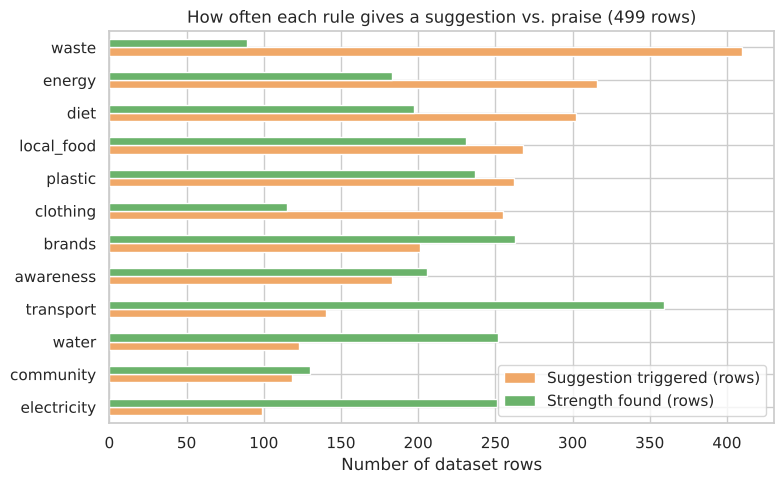

In [46]:
# Run the engine on every dataset row (full lists, not just the top 5) to see how the rules behave overall
from collections import Counter
rec_counter, strength_counter, top_priority, n_triggered = Counter(), Counter(), Counter(), []
for _, row in df.iterrows():
    p = {k: row[k] for k in REQUIRED_FIELDS}; p["SustainableBrands"] = bool(p["SustainableBrands"])
    full = generate_recommendations(p, max_recommendations=50, max_strengths=50)
    rec_counter.update(r["rule_id"] for r in full["recommendations"] if r["rule_id"] != "fallback_maintain")
    strength_counter.update(s["rule_id"] for s in full["strengths"])
    top_priority[full["recommendations"][0]["priority"]] += 1
    n_triggered.append(full["summary"]["suggestions_triggered"])

rule_table = pd.DataFrame({"Suggestion triggered (rows)": pd.Series(rec_counter), "Strength found (rows)": pd.Series(strength_counter)}).fillna(0).astype(int)
display(rule_table.sort_values("Suggestion triggered (rows)", ascending=False))
print("Highest priority shown first, across the dataset's rows:", dict(top_priority))
print(f"Suggestions triggered per row: mean {np.mean(n_triggered):.1f}, min {min(n_triggered)}, max {max(n_triggered)} (the engine shows at most 5)")
ax = rule_table.sort_values("Suggestion triggered (rows)").plot(kind="barh", figsize=(8, 5), color=["#f0a868", "#6bb36b"])
ax.set_xlabel("Number of dataset rows"); ax.set_title("How often each rule gives a suggestion vs. praise (499 rows)")
plt.tight_layout()
plt.show()

## 12. Original figures restored 


In [47]:
# The original figures used matplotlib's default style (no grid lines). The rest of this notebook uses seaborn's
# "whitegrid" theme, so for this section we go back to the default look. The theme is restored at the end of the section.
sns.reset_orig()

### 12.1 Data overview charts

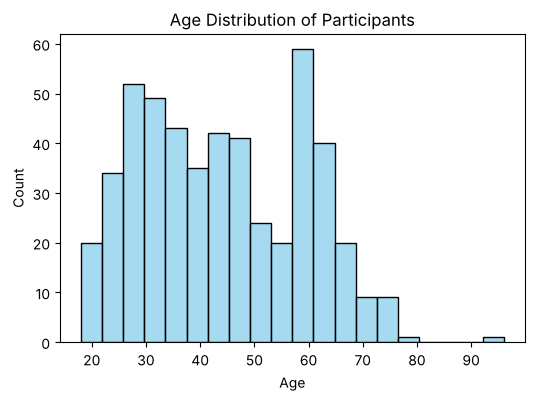

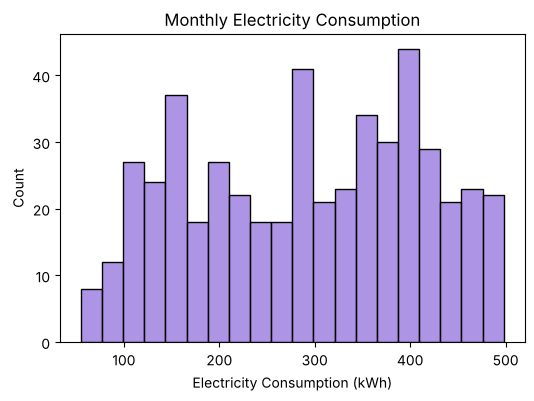

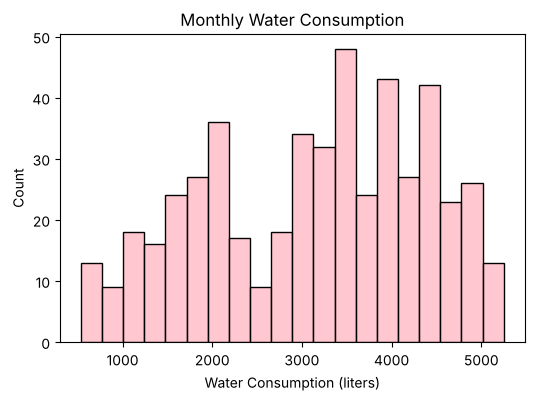

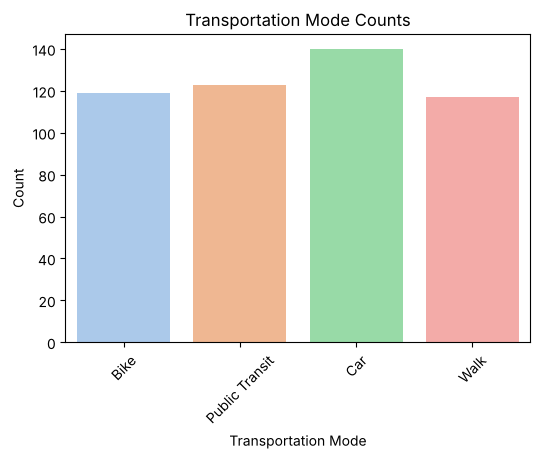

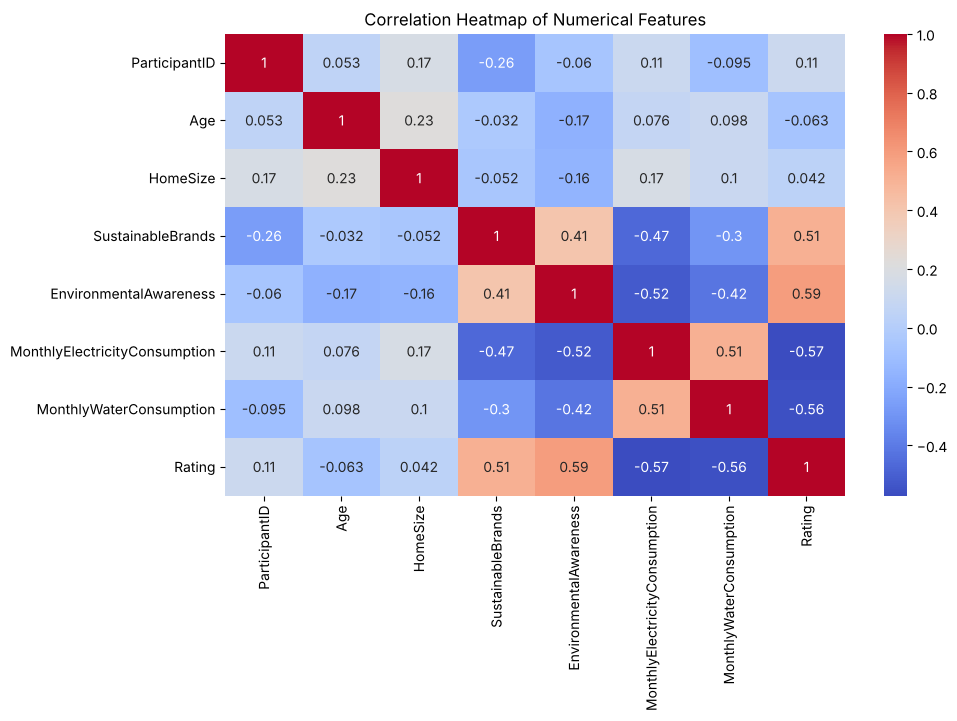

In [ ]:
# Correlation heatmap (numerical columns only, exactly as in the original notebook)
plt.figure(figsize=(10, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", cbar=True)
plt.title("Correlation Heatmap of Numerical Features")
plt.show()

*Note on chart 5:* as in the original figure, this heatmap includes `ParticipantID` (just a row identifier) and the True/False column `SustainableBrands`. They are shown only to match the original figure; `ParticipantID` is **not** a model feature. The correlation values are unchanged because the data is unchanged. The cleaner heatmap in Section 4.5 remains available.

### 12.2 Model charts from the corrected workflow 

**Chart 11 – Confusion matrix.** Same single-panel style as the original. It shows the **final tuned model on the untouched test set**, the same numbers as the left panel in Section 7.

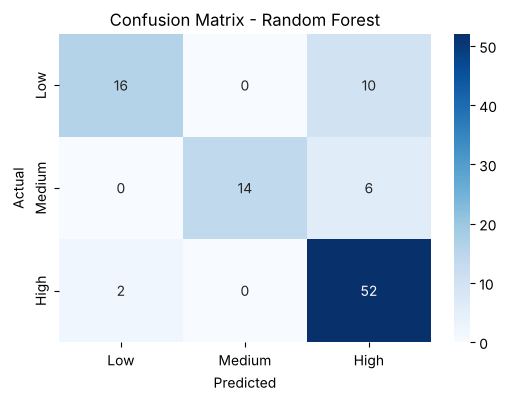

In [51]:
# Confusion matrix of the final model on the test set (y_pred was computed once in Section 7)
cm_original_style = confusion_matrix(y_test, y_pred, labels=CLASS_ORDER)

plt.figure(figsize=(6, 4))
sns.heatmap(cm_original_style, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_ORDER, yticklabels=CLASS_ORDER)
plt.title(f"Confusion Matrix - {best_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

**Chart 12 – Linear Regression, actual vs predicted.** Same purple scatter and red dashed "perfect fit" line as the original, using the corrected regression predictions (Section 9). **Title change:** the original title was *"Residuals Plot - Linear Regression"*, but the chart plots actual against predicted ratings, which is not a residual plot (a true residual plot is in Section 9). The title is corrected to *"Actual vs Predicted Ratings - Linear Regression"*; change that one string if your paper must keep the old wording.

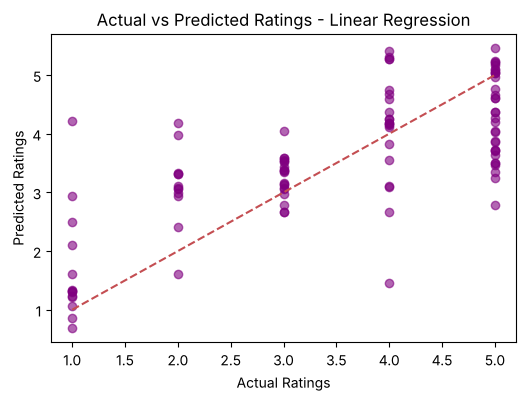

In [52]:
plt.figure(figsize=(6, 4))
plt.scatter(rating_test, rating_pred, color="purple", alpha=0.6)
plt.plot([rating_test.min(), rating_test.max()], [rating_test.min(), rating_test.max()], "r--")  # perfect fit line
plt.title("Actual vs Predicted Ratings - Linear Regression")
plt.xlabel("Actual Ratings")
plt.ylabel("Predicted Ratings")
plt.show()

**Chart 13 – Accuracy comparison across classification models.** Same three bars and colours as the original. **What changed:** the original plotted accuracy on one test split from a leaky workflow. Here each bar is the **mean 5-fold cross-validation accuracy on the training data** (default settings, leakage-free pipeline), so the test set is not reused for model selection.

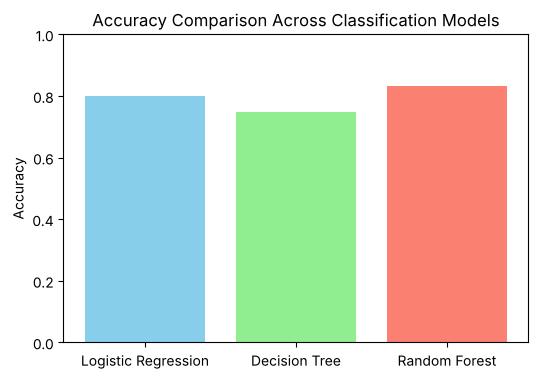

Mean 5-fold CV accuracy (training data):
  Logistic Regression: 0.8018
  Decision Tree: 0.7494
  Random Forest: 0.8319


In [53]:
# Mean cross-validation accuracy of each model (computed in Section 6)
accuracies = {
    "Logistic Regression": cv_results.loc["Logistic Regression", "accuracy_mean"],
    "Decision Tree": cv_results.loc["Decision Tree", "accuracy_mean"],
    "Random Forest": cv_results.loc["Random Forest", "accuracy_mean"],
}

plt.figure(figsize=(6, 4))
plt.bar(accuracies.keys(), accuracies.values(), color=["skyblue", "lightgreen", "salmon"])
plt.title("Accuracy Comparison Across Classification Models")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.show()

print("Mean 5-fold CV accuracy (training data):")
for model_name, accuracy_value in accuracies.items():
    print(f"  {model_name}: {accuracy_value:.4f}")

**Tuning both models (needed for charts 14 and 15).** The original tuned the Decision Tree and the Random Forest separately. The Random Forest was already tuned on the **training data only** in Section 7 (it was the strongest candidate), so that search is **reused** here. The Decision Tree is tuned now with the same grid, folds and macro-F1 scoring, also on training data only. The test set is not used.

In [54]:
tuning_models = ["Decision Tree", "Random Forest"]
tuned_searches = {}          # model name -> fitted GridSearchCV (training data only)

# Decision Tree: tune now with the grid defined in Section 7
tree_search = GridSearchCV(make_pipeline(models["Decision Tree"]), param_grids["Decision Tree"],
                           cv=cv, scoring=scoring["f1_macro"], n_jobs=1, refit=True)
tree_search.fit(X_train, y_train)
tuned_searches["Decision Tree"] = tree_search

# Random Forest: reuse the Section 7 search if Random Forest was the strongest candidate, otherwise tune it now
if best_name == "Random Forest":
    tuned_searches["Random Forest"] = grid
else:
    forest_search = GridSearchCV(make_pipeline(models["Random Forest"]), param_grids["Random Forest"],
                                 cv=cv, scoring=scoring["f1_macro"], n_jobs=1, refit=True)
    forest_search.fit(X_train, y_train)
    tuned_searches["Random Forest"] = forest_search

baseline_cv_accuracy = []    # accuracy of the default model (5-fold CV on training data)
tuned_cv_accuracy = []       # accuracy of the tuned model (5-fold CV on training data)
for model_name in tuning_models:
    search = tuned_searches[model_name]
    tuned_scores = cross_validate(search.best_estimator_, X_train, y_train, cv=cv, scoring="accuracy")
    baseline_cv_accuracy.append(cv_results.loc[model_name, "accuracy_mean"])
    tuned_cv_accuracy.append(tuned_scores["test_score"].mean())
    print(model_name, "- best parameters:", search.best_params_)

tuning_table = pd.DataFrame({"Model": tuning_models,
                             "Baseline CV accuracy": baseline_cv_accuracy,
                             "Tuned CV accuracy": tuned_cv_accuracy,
                             "Best CV macro F1": [tuned_searches[m].best_score_ for m in tuning_models]})
display(tuning_table.round(4))

Decision Tree - best parameters: {'model__criterion': 'entropy', 'model__max_depth': 8, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2}
Random Forest - best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 300}


,Model,Baseline CV accuracy,Tuned CV accuracy,Best CV macro F1
0,Decision Tree,0.7494,0.7645,0.7333
1,Random Forest,0.8319,0.8444,0.8064


**Chart 14 – Top 10 important features, Random Forest.** Same teal horizontal bar chart as the original, now for the **tuned Random Forest** fitted on the corrected 17-feature pipeline (so `Gender` and `ParticipantID` no longer appear, and `EnvironmentalAwareness` is a single numeric feature). Names ending in a category (for example `TransportationMode_Car`) are one-hot columns. As explained in Section 8.2, this is the model's internal importance, not evidence of cause and effect.

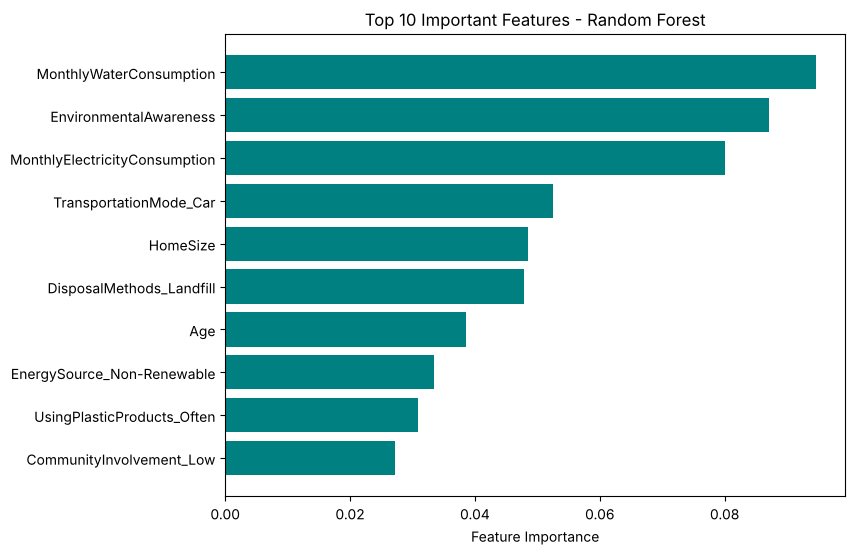

In [55]:
# Feature importance from the tuned Random Forest
tuned_rf_pipeline = tuned_searches["Random Forest"].best_estimator_
all_feature_names = tuned_rf_pipeline.named_steps["preprocess"].get_feature_names_out()
importances = tuned_rf_pipeline.named_steps["model"].feature_importances_
indices = np.argsort(importances)[-10:]          # positions of the 10 largest importances

# Remove the "num__" / "cat__" prefix added by ColumnTransformer so the labels are readable
top_feature_labels = [all_feature_names[i].split("__", 1)[1] for i in indices]

plt.figure(figsize=(8, 6))
plt.barh(range(len(indices)), importances[indices], align="center", color="teal")
plt.yticks(range(len(indices)), top_feature_labels)
plt.xlabel("Feature Importance")
plt.title("Top 10 Important Features - Random Forest")
plt.show()

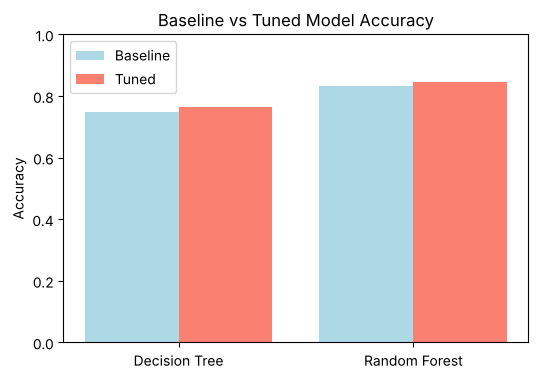

In [56]:
models_to_plot = ["Decision Tree", "Random Forest"]
baseline_acc = baseline_cv_accuracy
tuned_acc = tuned_cv_accuracy

x = range(len(models_to_plot))
plt.figure(figsize=(6, 4))
plt.bar(x, baseline_acc, width=0.4, label="Baseline", color="lightblue", align="center")
plt.bar([i + 0.4 for i in x], tuned_acc, width=0.4, label="Tuned", color="salmon", align="center")

plt.xticks([i + 0.2 for i in x], models_to_plot)
plt.ylabel("Accuracy")
plt.title("Baseline vs Tuned Model Accuracy")
plt.ylim(0, 1)
plt.legend()
plt.show()

### 12.3 Did the numbers change? Original notebook vs corrected workflow

In [57]:
sns.set_theme(style="whitegrid", context="notebook")   # restore the notebook-wide plot style used in the other sections

# "Original" values are copied from the saved outputs of the ORIGINAL notebook (test-set accuracy, old workflow).
# "Corrected" values come from this notebook (5-fold CV accuracy on training data, Section 6 and 12.4).
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree", "Random Forest"],
    "Original accuracy (old test split)": [0.81, 0.75, 0.88],
    "Corrected accuracy (CV, training data)": [accuracies["Logistic Regression"], accuracies["Decision Tree"], accuracies["Random Forest"]]})
display(comparison.round(3))

original_tuning = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "Original baseline": [0.63, 0.71], "Original tuned": [0.54, 0.75],
    "Corrected baseline (CV)": baseline_cv_accuracy, "Corrected tuned (CV)": tuned_cv_accuracy})
display(original_tuning.round(3))

print("Final tuned model on the untouched test set: accuracy = %.3f, macro F1 = %.3f" % (test_metrics["Accuracy"], test_metrics["Macro F1"]))
print("Linear Regression test set - original: RMSE 0.926, MAE 0.686, R2 0.659 | corrected: RMSE %.3f, MAE %.3f, R2 %.3f" % (
      reg_table.loc["RMSE", "Linear Regression (test)"], reg_table.loc["MAE", "Linear Regression (test)"], reg_table.loc["R²", "Linear Regression (test)"]))

,Model,Original accuracy (old test split),"Corrected accuracy (CV, training data)"
0,Logistic Regression,0.81,0.802
1,Decision Tree,0.75,0.749
2,Random Forest,0.88,0.832


,Model,Original baseline,Original tuned,Corrected baseline (CV),Corrected tuned (CV)
0,Decision Tree,0.63,0.54,0.749,0.764
1,Random Forest,0.71,0.75,0.832,0.844


Final tuned model on the untouched test set: accuracy = 0.820, macro F1 = 0.801
Linear Regression test set - original: RMSE 0.926, MAE 0.686, R2 0.659 | corrected: RMSE 0.961, MAE 0.725, R2 0.536
